# Phase 1: UDS Dataset Exploration & Variable Inventory

In this notebook, we load and examine the Uniform Data Set (UDS) to understand its structural dimensions, verify column names, and categorize clinical and cognitive variables for subsequent analysis.


In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

RAW = Path("../data/raw")
PROC = Path("../data/processed")

uds_raw = pd.read_csv(RAW / "udslong_imputed.csv", dtype={"NACCID": "string"}, low_memory=False)
print(f"Raw UDS -> rows: {uds_raw.shape[0]:,}, columns: {uds_raw.shape[1]}")


Raw UDS -> rows: 1,237, columns: 180


The dataset contains **180 columns** (variables) across multiple longitudinal observations. These variables encompass demographic information, clinical diagnoses, habits, and neuropsychological test scores (such as MoCA).

# Overview and Categorization of the 180 NACC UDS Variables

1. **Demographics (Variables 1–13):**
   - Core baseline subject profiles such as ID (`NACCID`), biological sex (`SEX`), race, education level (`EDUC` — crucial in Alzheimer's research for cognitive reserve), marital status, and age (`NACCAGE`).

2. **Family History (Variables 14–24):**
   - History of cognitive impairment, Alzheimer's disease (`NACCFADM`), or other dementias in mother, father, and close relatives.

3. **Habits (Variables 25–30):**
   - Prescription medication use, smoking history (duration, packs per day, and age of cessation).

4. **Medical History (Variables 31–74):**
   - History of cardiovascular diseases (myocardial infarction, atrial fibrillation), stroke (`CBSTROKE`), traumatic brain injury (`NACCTBI`), diabetes, hypertension, sleep disorders (apnea, RBD), and psychiatric conditions (depression, anxiety, schizophrenia).

5. **Medication Class (Variables 75–94):**
   - Indices or usage metrics for various drug classes (e.g., aspirin, antihypertensives, statins for hyperlipidemia, diabetes medications, and Parkinson's treatments).

6. **Physical / Vitals (Variables 95–108):**
   - Height, weight, systolic and diastolic blood pressure, heart rate, vision and hearing status, body mass index (`NACCBMI`), and neurological examination results.

7. **NPI-Q (Neuropsychiatric Inventory Questionnaire - Variables 109–133):**
   - Behavioral and psychological symptoms in dementia (e.g., delusions, hallucinations, agitation, depression, apathy, nighttime behavioral disturbances, and appetite changes) along with their respective severity ratings.

8. **GDS (Geriatric Depression Scale - Variables 134–150):**
   - 15 binary (yes/no) items assessing mood, feelings of hope, life satisfaction, and the total depression score (`NACCGDS`).

9. **Functional Activities (Variables 151–160):**
   - Subject's functional independence in complex daily tasks such as financial management (`BILLS`), taxes, shopping, stove usage, meal preparation, keeping track of current events, and traveling.

10. **Cognitive / Diagnostic (Variables 161–180):**
    - Standardized neuropsychological and clinical assessments, including category fluency (animals/vegetables - `ANIMALS`), Trail Making Tests (`TRAILA`, `TRAILB`), MoCA total score (`MOCATOTS`), genetic risk factors (`NACCAPOE` / APOE4 allele), final clinical consensus diagnosis (`NACCUDSD`), and Clinical Dementia Rating (CDR) domain scores (memory, orientation, judgment) along with summary totals (`CDRSUM` / `CDRGLOB`).


## 2. Unit of Observation and Data Structure

A row is the basic observational unit in a dataset. We used `NACCID` to
determine whether each participant contributes one row or multiple rows.

### Unit of observation

- **Clinical UDS dataset:** Each row represents one participant (`NACCID`) and
  the clinical information recorded for that participant in the selected
  assessment record.
- **MRI dataset:** Each row represents one participant (`NACCID`) and the MRI
  measurements recorded for that participant.

In the current cleaned files, each participant appears once in each dataset.
Therefore, each file contains one record per participant. The MRI and UDS
records are linked using `NACCID`.

### Data structure

The current files have a **one-row-per-participant, cross-sectional structure**.
No participant contributes multiple rows in either file, so the current
analysis files do not contain repeated observations per participant.


                 Current analysis files

     UDS clinical file                    MRI file
     1 row per NACCID                     1 row per NACCID
             │                                   │
             └──────── linked by NACCID ─────────┘
                         1:1 match

     Participant A: one UDS row + one MRI row
     Participant B: one UDS row + one MRI row
     ...


In [2]:
def check_structure(d, name):
    print("=" * 60)
    print(f"Dataset: {name} | rows: {len(d):,}")
    assert "NACCID" in d.columns, "NACCID column was not found"

    missing_ids = int(d["NACCID"].isna().sum())
    counts = d["NACCID"].dropna().value_counts()
    print(f"Unique NACCIDs: {d['NACCID'].nunique():,} | missing NACCIDs: {missing_ids}")
    print(f"Rows per participant: min {counts.min()}, max {counts.max()}")

    if counts.max() == 1 and missing_ids == 0:
        print("Result: one record per participant (visit not identifiable in this file).")
    else:
        print("Result: repeated records and/or missing IDs found.")
        print(counts.value_counts().sort_index().to_string())
    print("-" * 60)

uds = pd.read_csv(PROC / "udslong_cleaned.csv", dtype={"NACCID": "string"}, low_memory=False)
mri = pd.read_csv(PROC / "mriscan_cleaned.csv", dtype={"NACCID": "string"}, low_memory=False)

check_structure(uds, "Clinical UDS")
check_structure(mri, "MRI")


Dataset: Clinical UDS | rows: 1,237
Unique NACCIDs: 1,237 | missing NACCIDs: 0
Rows per participant: min 1, max 1
Result: one record per participant (visit not identifiable in this file).
------------------------------------------------------------
Dataset: MRI | rows: 1,237
Unique NACCIDs: 1,237 | missing NACCIDs: 0
Rows per participant: min 1, max 1
Result: one record per participant (visit not identifiable in this file).
------------------------------------------------------------



# 1. Overview and Variable Mapping of the UDS and MRI Datasets

This research relies on two core datasets that are linked 1:1 via a unique subject identifier (`NACCID`). Combining these sources provides a comprehensive profile of both clinical status and structural brain morphometry.

---

## A) UDS Clinical Dataset: Variable Categorization (180 Variables)

The clinical dataset captures longitudinal and cross-sectional non-imaging assessments, detailing participants' demographics, general health, daily functioning, and cognitive performance. These 180 variables are organized into 10 main domains:

1. **Demographics (Variables 1–13):**
   - Baseline data including subject ID (`NACCID`), biological sex (`SEX`), race, education level (`EDUC` — vital for cognitive reserve assessment), marital status, and age (`NACCAGE`).

2. **Family History (Variables 14–24):**
   - History of cognitive impairment, Alzheimer's disease (`NACCFADM`), or other dementias in biological parents and first-degree relatives.

3. **Habits & Lifestyle (Variables 25–30):**
   - Prescription drug usage and smoking patterns (duration, packs per year/day, and cessation age).

4. **Medical History & Comorbidities (Variables 31–74):**
   - Systemic health conditions such as cardiovascular disease, stroke history (`CBSTROKE`), traumatic brain injury (`NACCTBI`), diabetes, hypertension, sleep disorders (e.g., REM sleep behavior disorder), and psychiatric history.

5. **Medication Classes (Variables 75–94):**
   - Structured tracking of ongoing pharmacological treatments (antihypertensives, cholesterol-lowering statins, antidiabetic drugs, and Parkinson's therapeutics).

6. **Physical / Vitals & Neurological Examinations (Variables 95–108):**
   - Height, weight, systolic and diastolic blood pressure, resting heart rate, sensory impairments, and body mass index (`NACCBMI`).

7. **Neuropsychiatric Inventory Questionnaire (NPI-Q; Variables 109–133):**
   - Behavioral and psychological symptoms of dementia (such as delusions, hallucinations, agitation, apathy, and nighttime behavioral disturbances) along with their respective severity scores.

8. **Geriatric Depression Scale (GDS; Variables 134–150):**
   - 15 binary (yes/no) screening items evaluating depressive symptoms, life satisfaction, feelings of helplessness, and the aggregated depression score (`NACCGDS`).

9. **Functional Activities Questionnaire (FAQ; Variables 151–160):**
   - Instrumental activities of daily living (IADLs) evaluating real-world independence, such as managing finances (`BILLS`), grocery shopping, cooking, stove safety, and independent traveling.

10. **Cognitive, Neuropsychological & Diagnostic Profile (Variables 161–180):**
    - Specialized cognitive tests including category verbal fluency (`ANIMALS`, `VEG`), processing speed and executive functions (`TRAILA`, `TRAILB`), the MoCA test, genetic risk markers (`NACCAPOE`), CDR metrics (box and global scores), and the final clinical consensus diagnosis (`NACCUDSD`).

---

## B) MRI Neuroimaging Dataset: Structural Brain Features (126 Features)

This dataset includes volumetric and morphometric features extracted from the brain MRI scans of 1,237 participants, tracking structural changes across 31 bilateral regions of interest (ROIs):

1. **Identifiers & Clinical Consensus (2 variables):**
   - Includes `NACCID` for merging with clinical data and `NACCUDSD` representing the participant's diagnostic status (ranging from normal cognition to full dementia).

2. **Cortical Gray Matter Volume (`*_GVOL` — 62 variables):**
   - Regional volume in cubic millimeters ($mm^3$) across various cortical structures; reductions here indicate atrophy and neuronal loss (key regions for Alzheimer's include the entorhinal cortex, hippocampus, and posterior cingulate).

3. **Cortical Thickness (`*_AVGTH` — 62 variables):**
   - The mean distance ($mm$) between the pial surface and the gray-white matter boundary. This is a highly sensitive biomarker that often captures cortical thinning prior to gross volumetric shrinkage.

4. **Hemispheric Lateralization (`LH_` vs. `RH_`):**
   - All anatomical regions are measured independently for the **Left Hemisphere (`LH_`)** and **Right Hemisphere (`RH_`)**, allowing for the comparison of structural symmetry and disease progression patterns across hemispheres.

---

## C) Synthesis and Data Integration

- **Clinical Data (UDS)** describes the phenotypic expression of the individual (e.g., age, risk factors, functional independence, and cognitive test scores).
- **Neuroimaging Data (MRI)** quantifies the biological and physical changes in the brain (e.g., regional atrophy and cortical thickness).

By merging these two domains via the `NACCID` key, we can analyze how structural brain degradation correlates with real-world functional decline and cognitive impairment in patients.

In [3]:
print("UDS shape:", uds.shape)
print("MRI shape:", mri.shape)


UDS shape: (1237, 180)
MRI shape: (1237, 126)


In [4]:
gvol_vars  = [c for c in mri.columns if c.endswith("_GVOL")]
avgth_vars = [c for c in mri.columns if c.endswith("_AVGTH")]
feature_vars = gvol_vars + avgth_vars
id_vars    = [c for c in mri.columns if c not in feature_vars]   # NACCID and shared columns
lh_vars    = [c for c in feature_vars if c.startswith("LH_")]
rh_vars    = [c for c in feature_vars if c.startswith("RH_")]

assert len(feature_vars) == 124, len(feature_vars)
assert set(lh_vars) | set(rh_vars) == set(feature_vars)   # every feature is LH or RH

mri_summary = pd.DataFrame({
    "Category": ["Identifier / linkage", "Gray matter volume", "Cortical thickness",
                 "Left hemisphere features", "Right hemisphere features"],
    "Definition": [
        "Variables used to identify and merge participants across files",
        "Regional structural brain volume measures (_GVOL)",
        "Average cortical thickness by anatomical region (_AVGTH)",
        "Volume and thickness features of the left hemisphere (overlaps with the two rows above)",
        "Volume and thickness features of the right hemisphere (overlaps with the two rows above)",
    ],
    "Count": [len(id_vars), len(gvol_vars), len(avgth_vars), len(lh_vars), len(rh_vars)],
})
print("Identifier columns:", id_vars)
mri_summary



Identifier columns: ['NACCID', 'NACCUDSD']


,Category,Definition,Count
0,Identifier / linkage,Variables used to identify and merge participa...,2
1,Gray matter volume,Regional structural brain volume measures (_GVOL),62
2,Cortical thickness,Average cortical thickness by anatomical regio...,62
3,Left hemisphere features,Volume and thickness features of the left hemi...,62
4,Right hemisphere features,Volume and thickness features of the right hem...,62


In [5]:
import re

raw_mri = pd.read_csv(RAW / "mriscanclean.csv", dtype={"NACCID": "string"}, low_memory=False)
files = [("UDS (raw)", uds_raw), ("MRI (raw)", raw_mri)]

summary = []
for name, d in files:
    per = d.groupby("NACCID").size()
    summary.append({"File": name, "Records": len(d), "Unique participants": per.size,
                    "Min records": int(per.min()), "Max records": int(per.max()),
                    "Duplicated NACCID": int(d["NACCID"].duplicated().sum())})
print(pd.DataFrame(summary).to_string(index=False))

pat = re.compile(r"VISIT|VNUM|AVST|FDYS|NACCDAYS|MRIDATE|SCANDATE|_V\d$|_T\d$", re.I)
for name, d in files:
    print(f"Visit/date-like columns in {name}:", [c for c in d.columns if pat.search(c)] or "none")

assert set(uds_raw["NACCID"]) == set(raw_mri["NACCID"])
assert uds_raw["NACCID"].is_unique and raw_mri["NACCID"].is_unique
print("\nOne record per participant in both files; visit/date not identifiable "
      "(unit of analysis = one UDS record linked to one MRI record).")


     File  Records  Unique participants  Min records  Max records  Duplicated NACCID
UDS (raw)     1237                 1237            1            1                  0
MRI (raw)     1237                 1237            1            1                  0
Visit/date-like columns in UDS (raw): none
Visit/date-like columns in MRI (raw): none

One record per participant in both files; visit/date not identifiable (unit of analysis = one UDS record linked to one MRI record).


## C.2. Participant and Visit Structure Analysis

### A) Empirical Findings from the Analytical Datasets
We evaluated the participant-to-visit structure across both the clinical (`udslong_cleaned.csv`) and neuroimaging (`mriscan_cleaned.csv`) datasets:

1. **Unique Participants vs. Total Rows:**
   - **Clinical Dataset:** 1,237 total rows, 1,237 non-missing `NACCID` values, and **1,237 unique participants**.
   - **MRI Dataset:** 1,237 total rows, 1,237 non-missing `NACCID` values, and **1,237 unique participants**.
2. **Visit Distribution:**
   - In both files, **100% of participants have exactly one row** ($n = 1,237, 100\%$). No participant appears more than once ($0$ participants with $>1$ row).
   - Inspection of the clinical feature space confirms no longitudinal visit identifiers (such as `NACCVISIT`, `VISCODE`, or `EXAMDATE`) were retained in this processed snapshot.

### B) Scientific Interpretation
Although the source NACC cohort is inherently longitudinal, the curated dataset provided for this track has already been pre-filtered into a **cross-sectional, matched cohort**. Each participant's clinical profile represents a single, synchronized observation aligned with their structural MRI scan.

### C) Primary-Observation Selection Rule (Independence Guarantee)
In biomedical and statistical inference, treating repeated measures from the same subject as independent observations leads to pseudo-replication, deflated standard errors, and inflated Type I error rates. 

To guarantee the **independence of observations** assumption for downstream statistical analyses (e.g., hypothesis testing, regression models, classification):
1. **Pre-selected Linked Observation:** Because the working dataset has strictly one row per `NACCID`, each participant enters subsequent analyses as exactly **one independent statistical observation ($N = 1,237$)**.
2. **Theoretical Rule for Raw Longitudinal Data:** If the raw longitudinal NACC files were to be re-extracted, our primary selection rule would be to select the **index visit concurrent with the MRI acquisition** (within an acceptable temporal window, e.g., $\pm 90$ days), rather than selecting visits based on clinical outcome or extreme cognitive scores (which would introduce selection bias).
3. **Repeated Measures Handling:** Should multiple longitudinal visits be incorporated in future phases, they will not be treated as independent cases; instead, mixed-effects models (hierarchical linear modeling) or Generalized Estimating Equations (GEE) with patient-level clustering will be applied.


In [6]:
key = "NACCID"
for name, d in [("UDS", uds), ("MRI", mri)]:
    assert key in d.columns, f"{key} missing from {name}"
    assert d[key].notna().all(), f"{name}: missing {key}"
    assert d[key].is_unique, f"{name}: duplicate {key}"

ids_u, ids_m = set(uds[key]), set(mri[key])
shared_cols = [c for c in mri.columns if c in uds.columns and c != key]

print("=== UDS-MRI LINKAGE REPORT ===")
print(f"UDS participants: {len(ids_u):,} | MRI participants: {len(ids_m):,}")
print(f"In both: {len(ids_u & ids_m):,} | UDS-only: {len(ids_u - ids_m):,} | MRI-only: {len(ids_m - ids_u):,}")
print("Columns present in both files:", shared_cols)

linked = uds.merge(mri.drop(columns=shared_cols), on=key, how="inner", validate="one_to_one")
assert len(linked) == len(ids_u & ids_m) and linked[key].is_unique
print(f"Linked sample (inner join, 1:1): {len(linked):,} rows x {linked.shape[1]} columns")


=== UDS-MRI LINKAGE REPORT ===
UDS participants: 1,237 | MRI participants: 1,237
In both: 1,237 | UDS-only: 0 | MRI-only: 0
Columns present in both files: ['NACCUDSD']
Linked sample (inner join, 1:1): 1,237 rows x 304 columns



## Research Direction: Candidate Exploratory Hypotheses

To avoid blind data exploration across 300+ clinical and imaging variables, we frame our exploratory analysis around **six clinically motivated candidate questions**. These questions link demographic, cognitive, behavioral, and functional domains from the NACC UDS file with structural cortical measures (thickness and volume) from the MRI file.

The focal variables analyzed in subsequent sections (variable taxonomy, empirical distributions, summaries, and visualizations) are selected specifically to inform these candidate questions:


*Note: In Section 10, following data distribution checks, missingness audits, and initial visualizations, one primary statistical research question will be finalized for downstream modeling.*



### Question 1: Global Cognitive Status (MoCA) and Cortical Thickness
* **Question Text:**  
  *“Is a lower global cognitive score (MoCA) associated with reduced cortical thickness in key regions vulnerable to Alzheimer's disease, such as the entorhinal cortex, middle temporal gyrus, and precuneus?”*
* **Key Variables:**
  * **Clinical Outcome:** `MOCATOTS`
  * **MRI Predictors:** `LH_ENTORHINAL_AVGTH`, `RH_ENTORHINAL_AVGTH`, `LH_MIDDLETEMPORAL_AVGTH`, `RH_MIDDLETEMPORAL_AVGTH`, `LH_PRECUNEUS_AVGTH`, `RH_PRECUNEUS_AVGTH`
  * **Control Variables:** `NACCAGE`, `SEX`, `EDUC`
  * **Merge Key:** `NACCID`

---

### Question 2: Clinical Dementia Rating Sum of Boxes (CDRSUM) and Brain Atrophy
* **Question Text:**  
  *“Are higher levels of global clinical impairment, measured by the Clinical Dementia Rating Sum of Boxes (CDRSUM), correlated with decreased cortical thickness in temporal lobe structures?”*
* **Key Variables:**
  * **Clinical Predictor/Outcome:** `CDRSUM`
  * **MRI Variables:** `LH_ENTORHINAL_AVGTH`, `RH_ENTORHINAL_AVGTH`, `LH_PARAHIPPOCAMPAL_AVGTH`, `RH_PARAHIPPOCAMPAL_AVGTH`, `LH_MIDDLETEMPORAL_AVGTH`, `RH_MIDDLETEMPORAL_AVGTH`
  * **Control Variables:** `NACCAGE`, `SEX`, `EDUC`
  * **Merge Key:** `NACCID`

---

### Question 3: Specific Memory Impairment (CDR Memory Domain) and Medial Temporal Thickness
* **Question Text:**  
  *“Does the severity of impairment in the CDR memory domain specifically relate to cortical thinning in the entorhinal and parahippocampal cortices?”*
* **Key Variables:**
  * **Clinical Variable:** `MEMORY`
  * **MRI Variables:** `LH_ENTORHINAL_AVGTH`, `RH_ENTORHINAL_AVGTH`, `LH_PARAHIPPOCAMPAL_AVGTH`, `RH_PARAHIPPOCAMPAL_AVGTH`
  * **Control Variables:** `NACCAGE`, `SEX`, `EDUC`
  * **Merge Key:** `NACCID`

---

### Question 4: Instrumental Activities of Daily Living (IADL) and Frontal/Temporal Gray Matter Volume
* **Question Text:**  
  *“Is a decline in instrumental activities of daily living (IADL composite score) associated with reduced grey matter volume in frontal and temporal brain regions?”*
* **Key Variables:**
  * **Clinical Variables (IADL Composite):** `BILLS`, `TAXES`, `SHOPPING`, `GAMES`, `STOVE`, `MEALPREP`, `EVENTS`, `PAYATTN`, `REMDATES`, `TRAVEL`
  * **MRI Variables:** `LH_SUPERIORFRONTAL_GVOL`, `RH_SUPERIORFRONTAL_GVOL`, `LH_ROSTRALMIDDLEFRONTAL_GVOL`, `RH_ROSTRALMIDDLEFRONTAL_GVOL`, `LH_MIDDLETEMPORAL_GVOL`, `RH_MIDDLETEMPORAL_GVOL`, `LH_INFERIORTEMPORAL_GVOL`, `RH_INFERIORTEMPORAL_GVOL`
  * **Control Variables:** `NACCAGE`, `SEX`, `EDUC`
  * **Merge Key:** `NACCID`

---

### Question 5: Hemispheric Structural Asymmetry and Cognitive Decline
* **Question Text:**  
  *“Are left-right hemispheric structural asymmetries in cortical thickness associated with lower cognitive performance and increased dementia severity?”*
* **Key Variables:**
  * **MRI Asymmetry Index ($\text{AI}$):** Calculated from `LH_INSULA_AVGTH` & `RH_INSULA_AVGTH`, `LH_SUPERIORTEMPORAL_AVGTH` & `RH_SUPERIORTEMPORAL_AVGTH`, and `LH_ENTORHINAL_AVGTH` & `RH_ENTORHINAL_AVGTH`
  * **Clinical Outcomes:** `MOCATOTS` and `CDRSUM`
  * **Diagnostic Classification:** `NACCUDSD`
  * **Control Variables:** `NACCAGE`, `SEX`, `EDUC`
  * **Merge Key:** `NACCID`

---

### Question 6: Depressive Symptoms (GDS / History) and Limbic/Frontal Cortical Thickness
* **Question Text:**  
  *“Are depressive symptoms and higher geriatric depression scores (GDS) related to reduced cortical thickness in emotion-regulating brain regions, such as the insula, anterior cingulate, and orbitofrontal cortex?”*
* **Key Variables:**
  * **Clinical Variables:** `NACCGDS` (continuous score) and `DEP2YRS` (recent depression history)
  * **MRI Variables:** `LH_INSULA_AVGTH`, `RH_INSULA_AVGTH`, `LH_ROSTRALANTERIORCINGULATE_AVGTH`, `RH_ROSTRALANTERIORCINGULATE_AVGTH`, `LH_LATERALORBITOFRONTAL_AVGTH`, `RH_LATERALORBITOFRONTAL_AVGTH`
  * **Control Variables:** `NACCAGE`, `SEX`, `EDUC`
  * **Merge Key:** `NACCID`

## Task 4 — Variable Classification

To guide descriptive statistics, visualization, and subsequent inferential analyses, the main variables used in the selected research questions were classified by:

1. **domain** (clinical, MRI, demographic, or derived),
2. **analytical role** (outcome, predictor, control, grouping, or derived feature),
3. **measurement scale** (nominal, ordinal, quantitative discrete, or quantitative continuous).

This classification is important because it determines:
- which descriptive summaries should be reported,
- which visualizations are appropriate,
- and which statistical methods may be suitable in later stages of analysis.

In general:
- **Nominal variables** are summarized using frequency and percentage tables.
- **Ordinal variables** are summarized using frequency distributions and, when appropriate, medians or ordered-category plots.
- **Quantitative variables** are summarized using measures such as mean, standard deviation, median, quartiles, minimum, and maximum, together with empirical distribution plots.
- **Derived variables** such as asymmetry indices or composite scores require explicit construction rules before analysis.


| Variable | Domain | Analytical Role | Measurement Scale | Why this classification matters |
|---|---|---|---|---|
| `MOCATOTS` | Clinical cognitive | Main outcome | Quantitative discrete | Total MoCA score is numeric and ordered; should be summarized with center and spread, checked for ceiling effects, and analyzed as a cognitive outcome. |
| `CDRSUM` | Clinical severity | Main outcome / predictor depending on model | Quantitative continuous (practically score-like) | A summed clinical severity measure; suitable for distribution summaries and regression-based modeling, while checking skewness. |
| `MEMORY` | Clinical functional/cognitive domain | Main predictor / outcome depending on question | Ordinal | Represents ordered severity in the CDR memory domain; should be treated as ordered categories unless a continuous-score assumption is justified. |
| `NACCAGE` | Demographic | Control covariate | Quantitative continuous | Age is a continuous covariate and a major confounder in brain-cognition analyses. |
| `SEX` | Demographic | Control covariate | Nominal binary | Should be summarized with frequencies/percentages and treated as a grouping/control variable. |
| `EDUC` | Demographic / cognitive reserve | Control covariate | Quantitative discrete | Education is numeric, typically in years, and may affect both cognition and MRI markers. |
| `NACCUDSD` | Clinical diagnostic classification | Grouping / stratification variable | Nominal (or ordinal only if explicitly justified by coding) | Primarily used for grouping, descriptive comparison, and diagnostic stratification. |
| `NACCGDS` | Clinical mood | Main predictor / clinical feature | Quantitative discrete | Geriatric Depression Scale total score is numeric and should be summarized as a quantitative score. |
| `BILLS` | Clinical functional (IADL item) | Component of derived IADL composite | Ordinal | Ordered level of difficulty/impairment; should be summarized by category frequencies and used in composite-score construction. |
| `TAXES` | Clinical functional (IADL item) | Component of derived IADL composite | Ordinal | Ordered functional item contributing to IADL impairment score. |
| `SHOPPING` | Clinical functional (IADL item) | Component of derived IADL composite | Ordinal | Ordered functional item contributing to IADL impairment score. |
| `GAMES` | Clinical functional (IADL item) | Component of derived IADL composite | Ordinal | Ordered functional item contributing to IADL impairment score. |
| `STOVE` | Clinical functional (IADL item) | Component of derived IADL composite | Ordinal | Ordered functional item contributing to IADL impairment score. |
| `MEALPREP` | Clinical functional (IADL item) | Component of derived IADL composite | Ordinal | Ordered functional item contributing to IADL impairment score. |
| `EVENTS` | Clinical functional (IADL item) | Component of derived IADL composite | Ordinal | Ordered functional item contributing to IADL impairment score. |
| `PAYATTN` | Clinical functional (IADL item) | Component of derived IADL composite | Ordinal | Ordered functional item contributing to IADL impairment score. |
| `REMDATES` | Clinical functional (IADL item) | Component of derived IADL composite | Ordinal | Ordered functional item contributing to IADL impairment score. |
| `TRAVEL` | Clinical functional (IADL item) | Component of derived IADL composite | Ordinal | Ordered functional item contributing to IADL impairment score. |
| `LH_ENTORHINAL_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Continuous neuroanatomical measure; summarized with distribution statistics and used as a structural predictor. |
| `RH_ENTORHINAL_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Same as above for the right hemisphere. |
| `LH_MIDDLETEMPORAL_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Continuous cortical thickness measure for temporal cortex. |
| `RH_MIDDLETEMPORAL_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Continuous cortical thickness measure for temporal cortex. |
| `LH_PRECUNEUS_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Continuous cortical thickness measure; relevant to posterior cortical vulnerability. |
| `RH_PRECUNEUS_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Continuous cortical thickness measure; right-hemisphere counterpart. |
| `LH_PARAHIPPOCAMPAL_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Continuous thickness measure in medial temporal cortex. |
| `RH_PARAHIPPOCAMPAL_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Continuous thickness measure in medial temporal cortex. |
| `LH_INSULA_AVGTH` | MRI cortical thickness | Predictor / source for derived AI | Quantitative continuous | Used directly as a cortical thickness marker and as an input for asymmetry calculation. |
| `RH_INSULA_AVGTH` | MRI cortical thickness | Predictor / source for derived AI | Quantitative continuous | Used directly and for hemispheric asymmetry derivation. |
| `LH_SUPERIORTEMPORAL_AVGTH` | MRI cortical thickness | Predictor / source for derived AI | Quantitative continuous | Used directly and in asymmetry-index construction. |
| `RH_SUPERIORTEMPORAL_AVGTH` | MRI cortical thickness | Predictor / source for derived AI | Quantitative continuous | Used directly and in asymmetry-index construction. |
| `LH_ROSTRALANTERIORCINGULATE_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Continuous cortical thickness variable relevant to affective regulation. |
| `RH_ROSTRALANTERIORCINGULATE_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Right-hemisphere counterpart of anterior cingulate thickness. |
| `LH_LATERALORBITOFRONTAL_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Continuous frontal-limbic thickness marker. |
| `RH_LATERALORBITOFRONTAL_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Right-hemisphere counterpart. |
| `LH_MEDIALORBITOFRONTAL_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Continuous orbitofrontal thickness measure, relevant to affective and limbic circuits. |
| `RH_MEDIALORBITOFRONTAL_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Right-hemisphere counterpart. |
| `LH_SUPERIORFRONTAL_GVOL` | MRI gray matter volume | Predictor | Quantitative continuous | Continuous regional gray matter volume measure. |
| `RH_SUPERIORFRONTAL_GVOL` | MRI gray matter volume | Predictor | Quantitative continuous | Continuous regional gray matter volume measure. |
| `LH_ROSTRALMIDDLEFRONTAL_GVOL` | MRI gray matter volume | Predictor | Quantitative continuous | Continuous frontal gray matter volume measure. |
| `RH_ROSTRALMIDDLEFRONTAL_GVOL` | MRI gray matter volume | Predictor | Quantitative continuous | Continuous frontal gray matter volume measure. |
| `LH_MIDDLETEMPORAL_GVOL` | MRI gray matter volume | Predictor | Quantitative continuous | Continuous temporal gray matter volume measure. |
| `RH_MIDDLETEMPORAL_GVOL` | MRI gray matter volume | Predictor | Quantitative continuous | Continuous temporal gray matter volume measure. |
| `LH_INFERIORTEMPORAL_GVOL` | MRI gray matter volume | Predictor | Quantitative continuous | Continuous temporal gray matter volume measure. |
| `RH_INFERIORTEMPORAL_GVOL` | MRI gray matter volume | Predictor | Quantitative continuous | Continuous temporal gray matter volume measure. |
| `AI_Insula` | Derived MRI feature | Derived predictor | Quantitative continuous | Derived asymmetry index summarizing left-right imbalance in insular thickness. |
| `AI_SuperiorTemporal` | Derived MRI feature | Derived predictor | Quantitative continuous | Derived asymmetry index summarizing hemispheric imbalance in superior temporal thickness. |
| `AI_Entorhinal` | Derived MRI feature | Derived predictor | Quantitative continuous | Derived asymmetry index summarizing hemispheric imbalance in entorhinal thickness. |
| `IADL_Composite` | Derived clinical feature | Derived predictor | Quantitative discrete or approximately continuous | Composite score derived from 10 ordinal IADL items; may be analyzed as a summed impairment score after checking construction and distribution. |


### Derived Variables

Two types of derived variables are used in this project:

#### 1. IADL Composite Score
The IADL composite is constructed from the following ten functional items:

`BILLS`, `TAXES`, `SHOPPING`, `GAMES`, `STOVE`, `MEALPREP`, `EVENTS`, `PAYATTN`, `REMDATES`, `TRAVEL`

These variables are individual ordinal items, but their sum or standardized combination produces a derived composite variable representing overall functional impairment in instrumental activities of daily living.

If all items use the same coding direction, a higher composite score indicates greater IADL impairment.

#### 2. Hemispheric Asymmetry Indices
For selected cortical thickness measures, hemispheric asymmetry indices are constructed using:

\[
AI = \frac{LH - RH}{(LH + RH)/2}
\]

This formula is applied to:
- insula thickness,
- superior temporal thickness,
- entorhinal thickness.

These derived variables are quantitative continuous measures and can be used as structural predictors in relation to cognition and dementia severity.


| Variable | Domain | Analytical Role | Measurement Scale | Why this classification matters |
|---|---|---|---|---|
| `MOCATOTS` | Clinical cognitive | Main outcome | Quantitative discrete | Total MoCA score is numeric and ordered; should be summarized with center and spread, checked for ceiling effects, and analyzed as a cognitive outcome. |
| `CDRSUM` | Clinical severity | Main outcome / predictor depending on model | Quantitative continuous (practically score-like) | A summed clinical severity measure; suitable for distribution summaries and regression-based modeling, while checking skewness. |
| `MEMORY` | Clinical functional/cognitive domain | Main predictor / outcome depending on question | Ordinal | Represents ordered severity in the CDR memory domain; should be treated as ordered categories unless a continuous-score assumption is justified. |
| `NACCAGE` | Demographic | Control covariate | Quantitative continuous | Age is a continuous covariate and a major confounder in brain-cognition analyses. |
| `SEX` | Demographic | Control covariate | Nominal binary | Should be summarized with frequencies/percentages and treated as a grouping/control variable. |
| `EDUC` | Demographic / cognitive reserve | Control covariate | Quantitative discrete | Education is numeric, typically in years, and may affect both cognition and MRI markers. |
| `NACCUDSD` | Clinical diagnostic classification | Grouping / stratification variable | Nominal (or ordinal only if explicitly justified by coding) | Primarily used for grouping, descriptive comparison, and diagnostic stratification. |
| `NACCGDS` | Clinical mood | Main predictor / clinical feature | Quantitative discrete | Geriatric Depression Scale total score is numeric and should be summarized as a quantitative score. |
| `BILLS` | Clinical functional (IADL item) | Component of derived IADL composite | Ordinal | Ordered level of difficulty/impairment; should be summarized by category frequencies and used in composite-score construction. |
| `TAXES` | Clinical functional (IADL item) | Component of derived IADL composite | Ordinal | Ordered functional item contributing to IADL impairment score. |
| `SHOPPING` | Clinical functional (IADL item) | Component of derived IADL composite | Ordinal | Ordered functional item contributing to IADL impairment score. |
| `GAMES` | Clinical functional (IADL item) | Component of derived IADL composite | Ordinal | Ordered functional item contributing to IADL impairment score. |
| `STOVE` | Clinical functional (IADL item) | Component of derived IADL composite | Ordinal | Ordered functional item contributing to IADL impairment score. |
| `MEALPREP` | Clinical functional (IADL item) | Component of derived IADL composite | Ordinal | Ordered functional item contributing to IADL impairment score. |
| `EVENTS` | Clinical functional (IADL item) | Component of derived IADL composite | Ordinal | Ordered functional item contributing to IADL impairment score. |
| `PAYATTN` | Clinical functional (IADL item) | Component of derived IADL composite | Ordinal | Ordered functional item contributing to IADL impairment score. |
| `REMDATES` | Clinical functional (IADL item) | Component of derived IADL composite | Ordinal | Ordered functional item contributing to IADL impairment score. |
| `TRAVEL` | Clinical functional (IADL item) | Component of derived IADL composite | Ordinal | Ordered functional item contributing to IADL impairment score. |
| `LH_ENTORHINAL_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Continuous neuroanatomical measure; summarized with distribution statistics and used as a structural predictor. |
| `RH_ENTORHINAL_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Same as above for the right hemisphere. |
| `LH_MIDDLETEMPORAL_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Continuous cortical thickness measure for temporal cortex. |
| `RH_MIDDLETEMPORAL_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Continuous cortical thickness measure for temporal cortex. |
| `LH_PRECUNEUS_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Continuous cortical thickness measure; relevant to posterior cortical vulnerability. |
| `RH_PRECUNEUS_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Continuous cortical thickness measure; right-hemisphere counterpart. |
| `LH_PARAHIPPOCAMPAL_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Continuous thickness measure in medial temporal cortex. |
| `RH_PARAHIPPOCAMPAL_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Continuous thickness measure in medial temporal cortex. |
| `LH_INSULA_AVGTH` | MRI cortical thickness | Predictor / source for derived AI | Quantitative continuous | Used directly as a cortical thickness marker and as an input for asymmetry calculation. |
| `RH_INSULA_AVGTH` | MRI cortical thickness | Predictor / source for derived AI | Quantitative continuous | Used directly and for hemispheric asymmetry derivation. |
| `LH_SUPERIORTEMPORAL_AVGTH` | MRI cortical thickness | Predictor / source for derived AI | Quantitative continuous | Used directly and in asymmetry-index construction. |
| `RH_SUPERIORTEMPORAL_AVGTH` | MRI cortical thickness | Predictor / source for derived AI | Quantitative continuous | Used directly and in asymmetry-index construction. |
| `LH_ROSTRALANTERIORCINGULATE_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Continuous cortical thickness variable relevant to affective regulation. |
| `RH_ROSTRALANTERIORCINGULATE_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Right-hemisphere counterpart of anterior cingulate thickness. |
| `LH_LATERALORBITOFRONTAL_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Continuous frontal-limbic thickness marker. |
| `RH_LATERALORBITOFRONTAL_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Right-hemisphere counterpart. |
| `LH_MEDIALORBITOFRONTAL_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Continuous orbitofrontal thickness measure, relevant to affective and limbic circuits. |
| `RH_MEDIALORBITOFRONTAL_AVGTH` | MRI cortical thickness | Predictor | Quantitative continuous | Right-hemisphere counterpart. |
| `LH_SUPERIORFRONTAL_GVOL` | MRI gray matter volume | Predictor | Quantitative continuous | Continuous regional gray matter volume measure. |
| `RH_SUPERIORFRONTAL_GVOL` | MRI gray matter volume | Predictor | Quantitative continuous | Continuous regional gray matter volume measure. |
| `LH_ROSTRALMIDDLEFRONTAL_GVOL` | MRI gray matter volume | Predictor | Quantitative continuous | Continuous frontal gray matter volume measure. |
| `RH_ROSTRALMIDDLEFRONTAL_GVOL` | MRI gray matter volume | Predictor | Quantitative continuous | Continuous frontal gray matter volume measure. |
| `LH_MIDDLETEMPORAL_GVOL` | MRI gray matter volume | Predictor | Quantitative continuous | Continuous temporal gray matter volume measure. |
| `RH_MIDDLETEMPORAL_GVOL` | MRI gray matter volume | Predictor | Quantitative continuous | Continuous temporal gray matter volume measure. |
| `LH_INFERIORTEMPORAL_GVOL` | MRI gray matter volume | Predictor | Quantitative continuous | Continuous temporal gray matter volume measure. |
| `RH_INFERIORTEMPORAL_GVOL` | MRI gray matter volume | Predictor | Quantitative continuous | Continuous temporal gray matter volume measure. |
| `AI_Insula` | Derived MRI feature | Derived predictor | Quantitative continuous | Derived asymmetry index summarizing left-right imbalance in insular thickness. |
| `AI_SuperiorTemporal` | Derived MRI feature | Derived predictor | Quantitative continuous | Derived asymmetry index summarizing hemispheric imbalance in superior temporal thickness. |
| `AI_Entorhinal` | Derived MRI feature | Derived predictor | Quantitative continuous | Derived asymmetry index summarizing hemispheric imbalance in entorhinal thickness. |
| `IADL_Composite` | Derived clinical feature | Derived predictor | Quantitative discrete or approximately continuous | Composite score derived from 10 ordinal IADL items; may be analyzed as a summed impairment score after checking construction and distribution. |


### Why this classification matters for later analyses

This classification directly determines the statistical summaries and visualizations used in the next steps:

- **Nominal variables** such as `SEX` and `NACCUDSD` should be summarized using counts and percentages and visualized using bar plots.
- **Ordinal variables** such as `MEMORY` and the IADL items should be summarized with frequency tables and ordered-category plots; medians may be more informative than means.
- **Quantitative continuous MRI variables** should be summarized using mean, standard deviation, median, quartiles, range, and empirical distribution plots (e.g., histograms, density plots, boxplots).
- **Clinical score variables** such as `MOCATOTS`, `CDRSUM`, and `NACCGDS` should be checked for skewness, floor/ceiling effects, and outliers before selecting correlation methods.
- **Derived variables** such as asymmetry indices and the IADL composite require explicit construction and validation before inferential analysis.


In [7]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
RAW, P, FIG = Path("../data/raw"), Path("../data/processed"), Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

IADL  = ["BILLS", "TAXES", "SHOPPING", "GAMES", "STOVE", "MEALPREP", "EVENTS", "PAYATTN", "REMDATES", "TRAVEL"]
IADL8 = [c for c in IADL if c not in ("BILLS", "TAXES")]

def rho(data, a, b):
    """Spearman correlation on pairwise-complete data (DataFrame.corr needs no scipy)."""
    return data[[a, b]].dropna().corr(method="spearman").iloc[0, 1]

def med_iqr(s):
    q1, q2, q3 = s.dropna().quantile([0.25, 0.5, 0.75])
    return f"{q2:.2f} ({q1:.2f}-{q3:.2f})"

# Structural correlates of clinical severity in Alzheimer's disease (NACC UDS + MRI)

**Aim.** To describe the NACC UDS and MRI data, clean and link them, choose a feasible research question, and state a final statistical question supported by the data (no inferential claims at this stage).

**Workflow.** (1) Participant structure → (2) cleaning, linkage and sensitivity → (3) categorical variables → (4) quantitative variables → (5) missing data and choice of question → (6) summaries and figures → (7) descriptive group comparison → (8) final statistical question.

**Candidate questions.** Six questions were examined: (Q1) global cognition (MoCA) and cortical thickness; (Q2) global clinical severity (CDR Sum of Boxes) and temporal cortical thickness; (Q3) CDR memory severity and medial temporal thickness; (Q4) functional impairment (IADL) and gray-matter volume; (Q5) hemispheric asymmetry and cognitive decline; (Q6) depressive symptoms and limbic/frontal thickness.

**Retained: Q2.** It has the most complete data (98.8% complete cases). Q3 was merged into it because the memory score is almost the same variable as the CDR sum (Spearman ρ = 0.94). Q1 and Q5 were dropped (MoCA missing in 20.5%, more often in cognitively normal participants), Q4 (IADL items probably imputed upstream; no intracranial volume to adjust volumes) and Q6 (weak descriptive signal).

## 2. Data cleaning and linkage

**Source files.** `udslong_imputed.csv` (clinical, UDS) and `mriscanclean.csv` (MRI). The UDS file had already been imputed upstream: values that are multiples of 0.2 (e.g. 24.6 for MoCA, 0.2 or 1.8 for categorical items) are consistent with an average of five neighbours, and some (e.g. MoCA 39.4, DEP2YRS 1.8) can only arise if an error code such as 88 or 9 was among the neighbours. Error codes were then recoded in `udslong_cleaned.csv`. Imputed values that happen to be whole numbers cannot be told apart from observed ones. The number of NaN values after cleaning is therefore only a *lower bound* of the entries that were originally missing; it must not be read as the true amount of missing data, especially for the IADL items.

**UDS rules (`uds_final.csv`).** A value is set to NaN if it is outside the valid set or range, or is a non-integer score: IADL items ∈ {0,1,2,3}; `DEP2YRS` ∈ {0,1}; `SEX` ∈ {1,2}; `NACCUDSD` ∈ {1,2,3,4}; `MEMORY` ∈ {0, 0.5, 1, 2, 3}; `CDRSUM` between 0 and 18 in steps of 0.5; `EDUC` integer 0–36; `MOCATOTS` integer 0–30; `NACCGDS` integer 0–15; `NACCAGE` between 18 and 110 (a plausibility bound for adults; the observed range is 41–91). Variables of the final question (`CDRSUM`, `MEMORY`, `SEX`, `NACCAGE`) needed no correction. The earlier recoding script treated 88 and 99 as error codes in non-score columns, but they can be genuine ages; `NACCAGE` was therefore compared with the raw file and found identical.

**MRI rules (`mri_final.csv`)**, applied to the 124 thickness (`_AVGTH`) and volume (`_GVOL`) variables:
1. A value is flagged if it is *implausible* (thickness outside 1.0–4.5 mm, volume ≤ 0; these are plausibility bounds chosen here, not documented limits of the method) or lies beyond 3 × IQR from the quartiles of that variable.
2. Participants with ≥ 13 flagged values (≈ 10% of variables) have all MRI values set to NaN (unreliable scan; 12 participants, 563 flagged values).
3. For all others, a flagged low value is kept if it is ≥ 50% of the variable's median (possible genuine atrophy; 74 values restored); the remaining flagged values are set to NaN (64 values).

The rules use only MRI data, never the diagnosis or clinical scores. The thresholds are judgement calls: Section 2c shows how the main descriptive results change under alternative thresholds.

**Linkage.** UDS and MRI were linked on `NACCID` with a one-to-one inner join (1,237 participants). Columns present in both files (`NACCUDSD`) were checked for equality, treating "missing in both" as equal. Derived variables: two IADL composites, three asymmetry indices, bilateral mean thickness of three regions (`TH_*`, NaN if either hemisphere is missing) and `CDR_nonmemory = CDRSUM − MEMORY`. The IADL composites, asymmetry indices and `CDR_nonmemory` are exploratory and are not used in the final question.

**IADL composites.** `IADL_prorated` is the mean of the available items × 10 (at least 8 of 10 items required). `IADL_8items` is the sum of the 8 items other than `BILLS` and `TAXES`, which are the most frequently missing items (6.6% and 10.4% versus ≤ 1.7% for the others; 52 and 54 of the 56 participants with exactly 8 answered items lack them); it is a sensitivity version, not a complete-case version of the same score. Items are coded 0 = normal to 3 = dependent, so higher scores mean more impairment *(confirm the coding direction in the NACC codebook)*.

In [8]:
RULES = {
    **{c: {"values": {0, 1, 2, 3}} for c in IADL},
    "DEP2YRS":  {"values": {0, 1}},
    "SEX":      {"values": {1, 2}},
    "NACCUDSD": {"values": {1, 2, 3, 4}},
    "MEMORY":   {"values": {0, 0.5, 1, 2, 3}},
    "CDRSUM":   {"range": (0, 18), "step": 0.5},
    "NACCAGE":  {"range": (18, 110)},
    "EDUC":     {"range": (0, 36), "integer": True},
    "MOCATOTS": {"range": (0, 30), "integer": True},
    "NACCGDS":  {"range": (0, 15), "integer": True},
}

uds = pd.read_csv(P / "udslong_cleaned.csv", dtype={"NACCID": "string"},
                  keep_default_na=False, na_values=[""], low_memory=False)
n0 = len(uds)

report = []
for col, r in RULES.items():
    x = pd.to_numeric(uds[col], errors="coerce")
    ok = x.isin(r["values"]) if "values" in r else x.between(*r["range"])
    if r.get("integer"):
        ok &= (x % 1 == 0)
    if "step" in r:
        ok &= ((x / r["step"]) % 1 == 0)
    report.append({"Variable": col,
                   "Missing before": int(x.isna().sum()),
                   "Set to NaN (invalid)": int((x.notna() & ~ok).sum()),
                   "Missing after": int((~ok).sum())})
    uds[col] = x.where(ok)

rep = pd.DataFrame(report).set_index("Variable")
print(rep.to_string())

core = ["SEX", "NACCUDSD", "MEMORY", "CDRSUM", "NACCAGE"]
assert (rep.loc[core, "Set to NaN (invalid)"] == 0).all(), "invalid values in core variables"



age_raw = (pd.read_csv(RAW / "udslong_imputed.csv", usecols=["NACCID", "NACCAGE"], dtype={"NACCID": "string"})
             .set_index("NACCID")["NACCAGE"])
assert (uds["NACCID"].map(age_raw) == uds["NACCAGE"]).all(), "NACCAGE was altered by the recoding step"
print("NACCAGE identical to raw file; range", int(uds["NACCAGE"].min()), "-", int(uds["NACCAGE"].max()))

assert len(uds) == n0 == 1237 and uds["NACCID"].is_unique
uds.to_csv(P / "uds_final.csv", index=False)

          Missing before  Set to NaN (invalid)  Missing after
Variable                                                     
BILLS                 63                    19             82
TAXES                108                    21            129
SHOPPING               0                     6              6
GAMES                  0                     7              7
STOVE                  0                     2              2
MEALPREP               0                    14             14
EVENTS                 0                     6              6
PAYATTN                0                    13             13
REMDATES               0                    21             21
TRAVEL                 0                    18             18
DEP2YRS                0                    16             16
SEX                    0                     0              0
NACCUDSD               0                     0              0
MEMORY                 0                     0              0
CDRSUM  

In [9]:
def clean_mri(X, k=3.0, thr_scan=13, ratio=0.5):
    th = [c for c in X.columns if c.endswith("_AVGTH")]
    vol = [c for c in X.columns if c.endswith("_GVOL")]
    q1, q3, med = X.quantile(0.25), X.quantile(0.75), X.median()
    lo, hi = q1 - k * (q3 - q1), q3 + k * (q3 - q1)
    phys = pd.concat([(X[th] < 1.0) | (X[th] > 4.5), X[vol] <= 0], axis=1)[X.columns]   
    flagged = (phys | X.lt(lo, axis=1) | X.gt(hi, axis=1)) & X.notna()
    bad_scan = flagged.sum(axis=1) >= thr_scan                                          
    restore = flagged & ~phys & X.lt(lo, axis=1) & X.div(med, axis=1).ge(ratio)        
    clean = X.mask(flagged & ~restore)
    clean.loc[bad_scan, :] = np.nan
    return clean, flagged, restore, bad_scan, phys

mri = pd.read_csv(RAW / "mriscanclean.csv", dtype={"NACCID": "string"}, low_memory=False)
cols = [c for c in mri.columns if c.endswith(("_AVGTH", "_GVOL"))]
assert len(cols) == 124 and mri["NACCID"].is_unique

X = mri.set_index("NACCID")[cols].apply(pd.to_numeric, errors="coerce")
clean, flagged, restore, bad_scan, phys = clean_mri(X)


r, c = np.where(flagged.to_numpy())
log = pd.DataFrame({"NACCID": flagged.index[r], "Variable": np.array(cols)[c],
                    "Original_value": X.to_numpy()[r, c],
                    "Action": np.where(restore.to_numpy()[r, c], "restored", "NaN")})
log.loc[log["NACCID"].isin(bad_scan.index[bad_scan]), "Action"] = "NaN (whole scan)"

print(log["Action"].value_counts())

vc = log["Action"].value_counts()
assert vc["NaN (whole scan)"] == 563 and vc["restored"] == 74 and vc["NaN"] == 64, vc.to_dict()
assert len(log) == 701 and int(bad_scan.sum()) == 12

print(vc.to_string())
print("Whole scans removed:", int(bad_scan.sum()),
      "| participants with >= 1 missing MRI value:", int(clean.isna().any(axis=1).sum()))


out = mri.copy()
out[cols] = clean.to_numpy()
assert len(out) == 1237
out.to_csv(P / "mri_final.csv", index=False)
log.to_csv(P / "mri_cleaning_log.csv", index=False)

Action
NaN (whole scan)    563
restored             74
NaN                  64
Name: count, dtype: int64
Action
NaN (whole scan)    563
restored             74
NaN                  64
Whole scans removed: 12 | participants with >= 1 missing MRI value: 43


In [10]:
uds_f = pd.read_csv(P / "uds_final.csv", dtype={"NACCID": "string"}, low_memory=False)
mri_f = pd.read_csv(P / "mri_final.csv", dtype={"NACCID": "string"}, low_memory=False)

ids_u, ids_m = set(uds_f["NACCID"]), set(mri_f["NACCID"])
print(f"UDS {len(ids_u):,} | MRI {len(ids_m):,} | in both {len(ids_u & ids_m):,} | "
      f"UDS-only {len(ids_u - ids_m):,} | MRI-only {len(ids_m - ids_u):,}")

dup = [c for c in mri_f.columns if c in uds_f.columns and c != "NACCID"]
chk = uds_f[["NACCID"] + dup].merge(mri_f[["NACCID"] + dup], on="NACCID", suffixes=("_u", "_m"))
for c in dup:
    same = (chk[f"{c}_u"] == chk[f"{c}_m"]) | (chk[f"{c}_u"].isna() & chk[f"{c}_m"].isna())
    assert same.all(), c
print("Columns present in both files:", dup, "- values identical")

df = uds_f.merge(mri_f.drop(columns=dup), on="NACCID", how="inner", validate="one_to_one")
assert len(df) == 1237 and df["NACCID"].is_unique
assert all(c in df.columns for c in IADL + IADL8), "IADL columns missing"


n_ans = df[IADL].notna().sum(axis=1)
def asym(l, r):                     
    return ((df[l] - df[r]) / ((df[l] + df[r]) / 2)).replace([np.inf, -np.inf], np.nan)
def bilateral(region):               # NaN if either hemisphere is missing
    return df[[f"LH_{region}_AVGTH", f"RH_{region}_AVGTH"]].mean(axis=1, skipna=False)

new = pd.DataFrame({
    "IADL_prorated": np.where(n_ans >= 8, df[IADL].mean(axis=1) * 10, np.nan),
    "IADL_8items":   df[IADL8].sum(axis=1).where(df[IADL8].notna().all(axis=1)),
    "AI_Insula":           asym("LH_INSULA_AVGTH", "RH_INSULA_AVGTH"),
    "AI_SuperiorTemporal": asym("LH_SUPERIORTEMPORAL_AVGTH", "RH_SUPERIORTEMPORAL_AVGTH"),
    "AI_Entorhinal":       asym("LH_ENTORHINAL_AVGTH", "RH_ENTORHINAL_AVGTH"),
    "TH_ENTORHINAL":      bilateral("ENTORHINAL"),
    "TH_PARAHIPPOCAMPAL": bilateral("PARAHIPPOCAMPAL"),
    "TH_MIDDLETEMPORAL":  bilateral("MIDDLETEMPORAL"),
    "CDR_nonmemory":      df["CDRSUM"] - df["MEMORY"],
})
df = pd.concat([df, new], axis=1)
df.to_csv(P / "analysis_dataset.csv", index=False)
print("analysis_dataset.csv:", df.shape)

UDS 1,237 | MRI 1,237 | in both 1,237 | UDS-only 0 | MRI-only 0
Columns present in both files: ['NACCUDSD'] - values identical
analysis_dataset.csv: (1237, 313)


In [11]:
cdr = uds_f.set_index("NACCID")["CDRSUM"]
bil = lambda cl, reg: cl[[f"LH_{reg}_AVGTH", f"RH_{reg}_AVGTH"]].mean(axis=1, skipna=False)

scenarios = {
    "Main (3xIQR, 13 flags, 50%)":        dict(),
    "Stricter fences (2xIQR)":            dict(k=2.0),
    "Looser fences (4xIQR)":              dict(k=4.0),
    "Drop scan at >= 8 flags":            dict(thr_scan=8),
    "Drop scan at >= 20 flags":           dict(thr_scan=20),
    "Keep low values only if >= 70%":     dict(ratio=0.7),
    "Never restore low values":           dict(ratio=np.inf),
}
rows = []
for name, kw in scenarios.items():
    cl, fl, rs, bad, _ = clean_mri(X, **kw)
    d = pd.DataFrame({"CDRSUM": cdr, "ENT": bil(cl, "ENTORHINAL"), "PARA": bil(cl, "PARAHIPPOCAMPAL"), "MID": bil(cl, "MIDDLETEMPORAL")})
    rows.append({"Scenario": name, "Scans removed": int(bad.sum()), "Usable entorhinal n": int(d["ENT"].notna().sum()),
                 "Median ENT, CDRSUM=0": round(d.loc[d["CDRSUM"] == 0, "ENT"].median(), 2),
                 "Median ENT, CDRSUM>=5": round(d.loc[d["CDRSUM"] >= 5, "ENT"].median(), 2),
                 "rho ENT": round(rho(d, "CDRSUM", "ENT"), 2), "rho PARA": round(rho(d, "CDRSUM", "PARA"), 2),
                 "rho MID": round(rho(d, "CDRSUM", "MID"), 2)})
print(pd.DataFrame(rows).to_string(index=False))

                      Scenario  Scans removed  Usable entorhinal n  Median ENT, CDRSUM=0  Median ENT, CDRSUM>=5  rho ENT  rho PARA  rho MID
   Main (3xIQR, 13 flags, 50%)             12                 1224                  3.11                   2.69    -0.31     -0.25    -0.31
       Stricter fences (2xIQR)             20                 1215                  3.11                   2.69    -0.30     -0.24    -0.30
         Looser fences (4xIQR)              7                 1230                  3.11                   2.69    -0.30     -0.25    -0.31
       Drop scan at >= 8 flags             19                 1217                  3.11                   2.69    -0.30     -0.24    -0.30
      Drop scan at >= 20 flags              9                 1227                  3.11                   2.69    -0.30     -0.25    -0.31
Keep low values only if >= 70%             12                 1224                  3.11                   2.69    -0.31     -0.25    -0.30
      Never restore 

In [12]:
def n_diff(old, new):
    a = pd.read_csv(P / old, dtype={"NACCID": "string"}, low_memory=False).set_index("NACCID")
    b = pd.read_csv(P / new, dtype={"NACCID": "string"}, low_memory=False).set_index("NACCID")
    c = a.columns.intersection(b.columns)
    a, b = a.loc[b.index, c], b[c]
    d = (a != b) & ~(a.isna() & b.isna())
    return int(d.to_numpy().sum()), d.any().loc[lambda s: s].index.tolist()[:10]

print("UDS:", n_diff("udslong_analysis_cleaned_v2.csv", "uds_final.csv"))   
print("MRI:", n_diff("mriscan_analysis_final.csv", "mri_final.csv"))       

UDS: (0, [])
MRI: (0, [])


In [13]:
kw = dict(dtype={"NACCID": "string"}, low_memory=False)
m_v2  = pd.read_csv(P / "udslong_analysis_cleaned_v2.csv", **kw)
m_f   = pd.read_csv(P / "uds_final.csv", **kw)
m_cl  = pd.read_csv(P / "udslong_cleaned.csv", **kw)

for name, d in [("cleaned", m_cl), ("v2", m_v2), ("final", m_f)]:
    print(name, "| MOCATOTS NaN:", int(d["MOCATOTS"].isna().sum()), "| shape:", d.shape)

m = pd.to_numeric(m_cl["MOCATOTS"], errors="coerce")
print(m[~m.between(0, 30) | (m % 1 != 0)].value_counts().head())


cleaned | MOCATOTS NaN: 0 | shape: (1237, 180)
v2 | MOCATOTS NaN: 253 | shape: (1237, 180)
final | MOCATOTS NaN: 253 | shape: (1237, 180)
MOCATOTS
25.8    19
27.4    16
26.4    15
25.6    15
27.8    14
Name: count, dtype: int64


In [14]:
m = pd.to_numeric(m_cl["MOCATOTS"], errors="coerce")
bad = ~m.between(0, 30) | (m % 1 != 0)
print("non-integer:", int((m % 1 != 0).sum()), "| out of 0-30:", int((~m.between(0, 30)).sum()), "| total bad:", int(bad.sum()))
print("integer-valued share among OK:", float((m[~bad] % 1 == 0).mean()))


non-integer: 249 | out of 0-30: 9 | total bad: 253
integer-valued share among OK: 1.0


## 1b. Data source, collection and sampling

**Source.** The clinical data come from the Uniform Data Set (UDS) of the National Alzheimer's Coordinating Center (NACC), a database fed by the NIA-funded Alzheimer's Disease Research Centers (ADRCs) in the United States, which evaluate volunteers with a standardized clinical protocol, with follow-up visits roughly once a year. The MRI file contains regional brain measures (cortical thickness and gray-matter volume) derived from structural MRI with an automated cortical parcellation. «Cortical measures were derived from 3T/1.5T structural T1-weighted MRI scans processed through the FreeSurfer automated cortical parcellation pipeline (Desikan–Killiany atlas), calculating regional average cortical thickness in millimeters and gray-matter volume in cubic millimeters (mm3mm3).».

**Design.** Observational, volunteer-based clinical cohort. There was no random sampling and no intervention, so only associations can be studied.

**Sample used here.** 1,237 participants with both UDS and MRI data (see Section 1d for the visit used). Median age 68 years (Q1–Q3: 63–74); 59.8% women; median education 16 years (14–18); diagnosis: 68.5% normal cognition, 20.4% MCI, 10.6% dementia, 0.6% impaired-not-MCI.

**Generalizability.** Participants are volunteers recruited and evaluated at research centres, are highly educated (median 16 years), and the diagnostic mix is determined by the centres' recruitment, not by the population. Moreover, only participants who also have a usable MRI are included. Results therefore describe this clinic-based cohort and should not be generalized to the general population or to community-dwelling older adults.

In [15]:
df = pd.read_csv(P / "analysis_dataset.csv", dtype={"NACCID": "string"}, low_memory=False)

print("Age (years):", med_iqr(df["NACCAGE"]), "| range", int(df["NACCAGE"].min()), "-", int(df["NACCAGE"].max()))
print(f"Age >= 65: {(df['NACCAGE'] >= 65).mean() * 100:.1f}%")
print("Education (years):", med_iqr(df["EDUC"]), f"| >= 16 years: {(df['EDUC'] >= 16).mean() * 100:.1f}%")
print(f"Women: {(df['SEX'] == 2).mean() * 100:.1f}%")
print((df["NACCUDSD"].value_counts(normalize=True).sort_index() * 100).round(1).rename("Diagnosis, %"))


for c in ("RACE", "HISPOR", "VISITYR"):
    if c in df.columns:
        print(f"\n{c}:\n{df[c].value_counts(dropna=False).sort_index()}")

Age (years): 68.00 (63.00-74.00) | range 41 - 91
Age >= 65: 69.8%
Education (years): 16.00 (14.00-18.00) | >= 16 years: 71.5%
Women: 59.8%
NACCUDSD
1.0    68.5
2.0     0.6
3.0    20.4
4.0    10.6
Name: Diagnosis, %, dtype: float64

RACE:
RACE
1.0     1022
2.0      160
3.0       15
5.0       26
50.0      14
Name: count, dtype: int64

HISPOR:
HISPOR
1.0       31
2.0       15
3.0        2
4.0        9
5.0        8
6.0        8
50.0       3
NaN     1161
Name: count, dtype: int64


## 1c. Map of the UDS and MRI subsets (J1)

**UDS (clinical) subset.** One row per participant (`NACCID`). Variables are grouped by domain:

| Domain | Variables (examples) | What they measure |
|---|---|---|
| Demographic | `NACCAGE`, `SEX`, `EDUC` | Age at visit (years), sex, years of education |
| Diagnosis | `NACCUDSD` | Clinician diagnostic category: normal, impaired-not-MCI, MCI, dementia |
| Clinical severity (CDR) | `CDRSUM`, `MEMORY` | CDR Sum of Boxes (sum of six domain ratings, 0–18) and the memory box (0, 0.5, 1, 2, 3) |
| Cognitive tests | `MOCATOTS`, `ANIMALS`, `VEG`, `TRAILA`, `TRAILB`, `BOSTON`, `WAIS` | Global cognition (MoCA, 0–30), verbal fluency, trail-making times, naming, digit/symbol tasks |
| Functional | 10 IADL items (`BILLS` … `TRAVEL`) | Ordinal difficulty (0 normal … 3 dependent) in instrumental activities of daily living |
| Mood | `NACCGDS`, `DEP2YRS` | Geriatric Depression Scale total (0–15); depression in the last two years (0/1) |
| Medical history / lifestyle | `DIABETES`, `HYPERTEN`, `SMOKYRS` | History of conditions and smoking |
| Neuropsychiatric | columns ending in `SEV` | NPI-Q symptom severity |

**MRI subset.** 124 structural-MRI variables = 31 cortical regions × 2 hemispheres (`LH_`, `RH_`) × 2 measures:
- `_AVGTH`: average cortical thickness of the region (mm);
- `_GVOL`: gray-matter volume of the region.

These are *structural* (anatomical) measures; they show how thick or large a cortical region is, not brain activity. Region names follow the Desikan–Killiany/FreeSurfer convention (e.g. entorhinal, parahippocampal, middle temporal, precuneus, insula). Atrophy appears as lower thickness or volume. 

**Derived variables** (created here): IADL composites, asymmetry indices, bilateral mean thickness (`TH_*`) and `CDR_nonmemory`.

In [16]:
derived = ["IADL_prorated", "IADL_8items", "AI_Insula", "AI_SuperiorTemporal", "AI_Entorhinal",
           "TH_ENTORHINAL", "TH_PARAHIPPOCAMPAL", "TH_MIDDLETEMPORAL", "CDR_nonmemory"]
domain_map = {
    "UDS: demographic":             ["NACCAGE", "SEX", "EDUC", "HISPOR", "RACE"],
    "UDS: diagnosis":               ["NACCUDSD"],
    "UDS: clinical severity (CDR)": ["CDRSUM", "MEMORY", "ORIENT", "JUDGMENT", "COMMUN", "HOMEHOBB", "PERSCARE", "CDRGLOB"],
    "UDS: cognitive tests":         ["MOCATOTS", "ANIMALS", "VEG", "TRAILA", "TRAILARR", "TRAILALI", "TRAILB",
                                     "TRAILBRR", "TRAILBLI", "WAIS", "BOSTON"],
    "UDS: functional (IADL)":       IADL,
    "UDS: mood":                    ["NACCGDS", "DEP2YRS"],
    "UDS: medical / lifestyle":     ["DIABETES", "HYPERTEN", "SMOKYRS"],
}
def domain(col):
    for k, v in domain_map.items():
        if col in v:
            return k
    if col in derived:            return "Derived"
    if col.endswith("_AVGTH"):    return "MRI: cortical thickness"
    if col.endswith("_GVOL"):     return "MRI: gray-matter volume"
    if col.endswith("SEV"):       return "UDS: neuropsychiatric (NPI-Q severity)"
    return "UDS: other (classify with the data dictionary)"

dom = pd.Series({c: domain(c) for c in df.columns if c != "NACCID"})
print(dom.value_counts().to_string())
print("\nStill unclassified:", sorted(dom[dom.str.contains("other")].index))

UDS: other (classify with the data dictionary)    129
MRI: gray-matter volume                            62
MRI: cortical thickness                            62
UDS: neuropsychiatric (NPI-Q severity)             12
UDS: functional (IADL)                             10
UDS: cognitive tests                                9
Derived                                             9
UDS: clinical severity (CDR)                        8
UDS: demographic                                    5
UDS: medical / lifestyle                            3
UDS: mood                                           2
UDS: diagnosis                                      1

Still unclassified: ['ABUSOTHR', 'AFRAID', 'AGIT', 'ALCOHOL', 'ANX', 'ANXIETY', 'ANYMEDS', 'APA', 'APNEA', 'APP', 'ARTHLOEX', 'ARTHRIT', 'ARTHSPIN', 'ARTHTYPE', 'ARTHUNK', 'ARTHUPEX', 'B12DEF', 'BETTER', 'BIPOLAR', 'BORED', 'BPDIAS', 'BPSYS', 'CBSTROKE', 'CBTIA', 'CVAFIB', 'CVANGIO', 'CVBYPASS', 'CVCHF', 'CVHATT', 'CVOTHR', 'CVPACDEF', 'DECSUB', 'DE

In [17]:
raw_uds = pd.read_csv(RAW / "udslong_imputed.csv", dtype={"NACCID": "string"}, low_memory=False)
raw_mri = pd.read_csv(RAW / "mriscanclean.csv", dtype={"NACCID": "string"}, low_memory=False)
for name, d in [("UDS (raw)", raw_uds), ("MRI (raw)", raw_mri)]:
    print(f"{name}: {len(d):,} rows | {d['NACCID'].nunique():,} unique participants | duplicated IDs: {int(d['NACCID'].duplicated().sum())}")

visit_cols = [c for c in ["NACCVNUM", "NACCAVST", "VISITYR", "VISITMO", "VISITDAY", "NACCFDYS", "NACCDAYS"] if c in raw_uds.columns]
print("\nVisit-related columns in the UDS file:", visit_cols or "none found")
if "NACCVNUM" in raw_uds.columns:
    print("\nVisit number of the row kept (NACCVNUM):"); print(raw_uds["NACCVNUM"].value_counts().sort_index())
if "NACCAVST" in raw_uds.columns:
    print("\nTotal UDS visits per participant (NACCAVST):")
    one = raw_uds.drop_duplicates("NACCID")["NACCAVST"]
    print(one.describe().round(2)); print(one.value_counts().sort_index())
if "VISITYR" in raw_uds.columns:
    print("\nVisit year range:", int(raw_uds["VISITYR"].min()), "-", int(raw_uds["VISITYR"].max()))

UDS (raw): 1,237 rows | 1,237 unique participants | duplicated IDs: 0
MRI (raw): 1,237 rows | 1,237 unique participants | duplicated IDs: 0

Visit-related columns in the UDS file: none found


## 1d. Participants, visits and the analysis observation (J2)

| | UDS file | MRI file |
|---|---|---|
| Rows | 1,237 | 1,237 |
| Unique participants (`NACCID`) | 1,237 | 1,237 |
| Duplicated `NACCID` | 0 | 0 |
**Visits.** Neither file contains a visit-number, visit-date or visit-count column (the search for such columns returned none), and every `NACCID` appears exactly once in both files. The files therefore contain a single record per participant, and the number of visits per participant cannot be described from these data.

**Rule for the main observation.** Each participant contributes exactly **one row** (one UDS record linked to one MRI record), so no participant enters any analysis more than once as an independent observation. The files do not state which visit this row comes from; this was decided when the files were prepared and is not recorded in the data we received. We therefore treat it as the single record supplied for each participant and list this as a limitation.

In [18]:
cdr_ok = (df["CDRSUM"] >= 0) & (df["CDRSUM"] <= 18) & ((df["CDRSUM"] * 2) % 1 == 0)
checks = {
    "Duplicated NACCID": int(df["NACCID"].duplicated().sum()),
    "CDRSUM outside 0-18 or not a multiple of 0.5": int((~cdr_ok).sum()),
    "CDRSUM < MEMORY (impossible: MEMORY is a part of the sum)": int((df["CDRSUM"] < df["MEMORY"]).sum()),
    "Age outside 18-110": int((~df["NACCAGE"].between(18, 110)).sum()),
    "Normal cognition (NACCUDSD = 1) with CDRSUM >= 3": int(((df["NACCUDSD"] == 1) & (df["CDRSUM"] >= 3)).sum()),
    "Dementia (NACCUDSD = 4) with CDRSUM = 0": int(((df["NACCUDSD"] == 4) & (df["CDRSUM"] == 0)).sum()),
    "Bilateral entorhinal thickness outside 1-4.5 mm": int((~df["TH_ENTORHINAL"].dropna().between(1, 4.5)).sum()),
    "Entorhinal |LH - RH| > 1 mm": int(((df["LH_ENTORHINAL_AVGTH"] - df["RH_ENTORHINAL_AVGTH"]).abs() > 1).sum()),
}
print(pd.Series(checks).to_string())

print("\nDiagnosis vs CDRSUM group (row %):")
print(pd.crosstab(df["NACCUDSD"], pd.cut(df["CDRSUM"], [-0.1, 0, 1.5, 4.5, np.inf], labels=["0", "0.5-1.5", "2-4.5", ">=5"]),
                  normalize="index").mul(100).round(1))

Duplicated NACCID                                             0
CDRSUM outside 0-18 or not a multiple of 0.5                  0
CDRSUM < MEMORY (impossible: MEMORY is a part of the sum)     0
Age outside 18-110                                            0
Normal cognition (NACCUDSD = 1) with CDRSUM >= 3              1
Dementia (NACCUDSD = 4) with CDRSUM = 0                       0
Bilateral entorhinal thickness outside 1-4.5 mm               0
Entorhinal |LH - RH| > 1 mm                                  14

Diagnosis vs CDRSUM group (row %):
CDRSUM       0  0.5-1.5  2-4.5   >=5
NACCUDSD                            
1.0       86.8     12.4    0.8   0.0
2.0       28.6     57.1   14.3   0.0
3.0        7.9     67.1   25.0   0.0
4.0        0.0      9.9   53.4  36.6


## 1e. Data-quality decisions (Task 5)

| Issue | Where | Decision | Reason |
|---|---|---|---|
| Error codes (777, 888, 998, 999; 8, 9, 88, 99 in non-score columns) | UDS | Set to NaN; for NPI-Q severity items code 8 recoded to 0 and 9 to NaN | They are not real measurements |
| Imputed (non-integer) values and out-of-range values | UDS: IADL items, `DEP2YRS`, `EDUC`, `MOCATOTS`, `NACCGDS` | Set to NaN | The source file had been imputed upstream; scores that must be integers cannot be non-integers, and error codes had contaminated the neighbour averages |
| Impossible MRI values | MRI | Thickness outside 1.0–4.5 mm or volume ≤ 0 set to NaN | Physically impossible |
| Extreme MRI outliers | MRI | Beyond 3 × IQR set to NaN, except low values ≥ 50% of the variable's median (kept as plausible atrophy) | Remove errors without deleting genuine atrophy; the rule never uses the diagnosis |
| Unreliable scans | MRI | ≥ 13 flagged values (≈ 10% of variables) → all MRI values NaN (12 participants) | One failed reconstruction contaminates all measures |
| Duplicates | both | None (`NACCID` unique) | – |
| Logical inconsistencies | UDS and MRI | Checked; no value changed. One participant with normal cognition and CDRSUM ≥ 3, and 14 participants with a left–right entorhinal difference > 1 mm, were kept and reported | No impossible combinations were found (CDRSUM < MEMORY: 0; dementia with CDRSUM = 0: 0; age outside 18–110: 0; entorhinal thickness outside 1–4.5 mm: 0). The few unusual cases may be real, so they were not deleted |
| Missing values in analysis | Q2, Q3 | Complete-case analysis (1,222 of 1,237) | Only 1.2% lost; missingness unrelated to the main exposure *(check in Section 4b)* |
| Missing values in analysis | Q2 | Complete-case analysis (1,222 of 1,237) | Only 1.2% of participants are lost. The 15 lost participants are too few to say whether they differ from the others (see Section 4b) |

In [19]:
df = pd.read_csv(P / "analysis_dataset.csv", dtype={"NACCID": "string"}, low_memory=False)

cat_labels = {  
    "SEX": {1: "Male", 2: "Female"},
    "NACCUDSD": {1: "Normal cognition", 2: "Impaired, not MCI", 3: "MCI", 4: "Dementia"},
    "DEP2YRS": {0: "No", 1: "Yes"},
    "MEMORY": {0: "0 None", 0.5: "0.5 Questionable", 1: "1 Mild", 2: "2 Moderate", 3: "3 Severe"},
}
iadl_levels = {0: "0 Normal", 1: "1 Difficulty, no help", 2: "2 Needs help", 3: "3 Dependent"}

def freq_table(s, labels):
    valid = s.dropna()
    assert valid.isin(list(labels)).all(), f"unexpected codes in {s.name}"
    t = pd.DataFrame({"Label": list(labels.values()), "n": [int((s == k).sum()) for k in labels]}, index=list(labels))
    t["% of valid"] = (100 * t["n"] / len(valid)).round(1)
    t.loc["NaN"] = ["Missing", int(s.isna().sum()), np.nan]
    return t

for var, labels in cat_labels.items():
    print(f"\n=== {var} ===")
    print(freq_table(df[var], labels).to_string())

counts = pd.DataFrame({i: df[i].value_counts().reindex(list(iadl_levels), fill_value=0) for i in IADL}).T
counts.columns = list(iadl_levels.values())
counts["Missing"] = df[IADL].isna().sum()
pct = counts[list(iadl_levels.values())].div(counts[list(iadl_levels.values())].sum(axis=1), axis=0).mul(100).round(1)
print("\n=== IADL items: counts ===");     print(counts.to_string())
print("\n=== IADL items: % of valid ===");  print(pct.to_string())


=== SEX ===
       Label    n  % of valid
1       Male  497        40.2
2     Female  740        59.8
NaN  Missing    0         NaN

=== NACCUDSD ===
                 Label    n  % of valid
1     Normal cognition  847        68.5
2    Impaired, not MCI    7         0.6
3                  MCI  252        20.4
4             Dementia  131        10.6
NaN            Missing    0         NaN

=== DEP2YRS ===
       Label    n  % of valid
0         No  987        80.8
1        Yes  234        19.2
NaN  Missing   16         NaN

=== MEMORY ===
                Label    n  % of valid
0.0            0 None  808        65.3
0.5  0.5 Questionable  264        21.3
1.0            1 Mild  148        12.0
2.0        2 Moderate   15         1.2
3.0          3 Severe    2         0.2
NaN           Missing    0         NaN

=== IADL items: counts ===
          0 Normal  1 Difficulty, no help  2 Needs help  3 Dependent  Missing
BILLS          988                     55            54           58       82

## 2. Categorical variables

| Variable | Scale | Levels | Used in |
|---|---|---|---|
| `SEX` | Nominal (binary) | 1 = Male, 2 = Female | covariate (all questions) |
| `NACCUDSD` | Nominal | 1 = Normal, 2 = Impaired not MCI, 3 = MCI, 4 = Dementia | sample description, Q5 |
| `DEP2YRS` | Nominal (binary) | 0 = No, 1 = Yes | Q6 |
| `MEMORY` | Ordinal | CDR memory box: 0, 0.5, 1, 2, 3 | Q3 |
| 10 IADL items | Ordinal | 0 = Normal … 3 = Dependent | Q4 |

**Findings.**
- **Sample.** 59.8% female. Diagnosis: 68.5% normal, 20.4% MCI, 10.6% dementia, and only 7 participants (0.6%) in "impaired, not MCI". The sample is clinic-based, not population-representative.
- **`MEMORY`.** 65.3% score 0, 21.3% score 0.5, 12.0% score 1, and only 17 participants (1.4%) score 2 or 3; these two levels are merged ("≥ 2") when `MEMORY` is analysed in groups.
- **IADL items.** All items are strongly concentrated in "normal" (79–93%); any impairment ranges from 6.7% (`STOVE`) to 20.9% (`REMDATES`). `BILLS` (6.6%) and `TAXES` (10.4%) have the most missing values, but because the other items were probably imputed upstream, their reported missingness is a lower bound.
- **Patterns by diagnosis.** `MEMORY` is almost step-like across diagnostic groups, but the diagnosis partly relies on the CDR, so this association is partly built in. Any IADL impairment on `BILLS`/`TAXES`/`REMDATES` rises from 2–7% (normal) to 23–35% (MCI) and 83–86% (dementia). Depression history (`DEP2YRS`) is more frequent in dementia (29.8%) than in normal (17.6%) or MCI (18.3%); the MCI group has more men (56.0%) than the normal group (35.7%).

In [20]:
th_regs = ["ENTORHINAL", "MIDDLETEMPORAL", "PRECUNEUS", "PARAHIPPOCAMPAL", "INSULA",
           "SUPERIORTEMPORAL", "ROSTRALANTERIORCINGULATE", "LATERALORBITOFRONTAL"]
gv_regs = ["SUPERIORFRONTAL", "ROSTRALMIDDLEFRONTAL", "MIDDLETEMPORAL", "INFERIORTEMPORAL"]
quant = {
    "Clinical / demographic":  ["MOCATOTS", "CDRSUM", "NACCAGE", "EDUC", "NACCGDS"],
    "Cortical thickness (mm)": [f"{h}_{r}_AVGTH" for r in th_regs for h in ("LH", "RH")],
    "Gray matter volume":      [f"{h}_{r}_GVOL" for r in gv_regs for h in ("LH", "RH")],
    "Derived":                 ["IADL_prorated", "IADL_8items", "AI_Insula", "AI_SuperiorTemporal", "AI_Entorhinal"],
}

def describe(cols):
    d = df[cols].describe().T
    d["missing"] = len(df) - d["count"]
    d["IQR"] = d["75%"] - d["25%"]
    d["skew"] = df[cols].skew()
    return d[["count", "missing", "mean", "std", "min", "25%", "50%", "75%", "max", "IQR", "skew"]].round(3)

for name, cols in quant.items():
    print(f"\n=== {name} ===")
    print(describe(cols).to_string())


=== Clinical / demographic ===
           count  missing    mean    std   min   25%   50%   75%   max   IQR   skew
MOCATOTS   984.0    253.0  24.028  4.739   0.0  22.0  25.0  27.0  30.0   5.0 -1.644
CDRSUM    1237.0      0.0   0.822  1.723   0.0   0.0   0.0   1.0  15.0   1.0  3.471
NACCAGE   1237.0      0.0  68.192  8.039  41.0  63.0  68.0  74.0  91.0  11.0 -0.252
EDUC      1235.0      2.0  16.257  2.719   0.0  14.0  16.0  18.0  25.0   4.0 -0.937
NACCGDS   1223.0     14.0   1.636  2.127   0.0   0.0   1.0   2.0  14.0   2.0  2.091

=== Cortical thickness (mm) ===
                                    count  missing   mean    std    min    25%    50%    75%    max    IQR   skew
LH_ENTORHINAL_AVGTH                1224.0     13.0  2.978  0.370  1.451  2.771  3.022  3.229  3.979  0.458 -0.547
RH_ENTORHINAL_AVGTH                1224.0     13.0  3.072  0.373  1.670  2.867  3.104  3.325  3.967  0.458 -0.638
LH_MIDDLETEMPORAL_AVGTH            1225.0     12.0  2.561  0.149  1.629  2.483  2.572  2.

## 2. Categorical variables

| Variable | Scale | Levels | Used in |
|---|---|---|---|
| `SEX` | Nominal (binary) | 1 = Male, 2 = Female | covariate (all questions) |
| `NACCUDSD` | Nominal | 1 = Normal, 2 = Impaired not MCI, 3 = MCI, 4 = Dementia | sample description, Q5 |
| `DEP2YRS` | Nominal (binary) | 0 = No, 1 = Yes | Q6 |
| `MEMORY` | Ordinal | CDR memory box: 0, 0.5, 1, 2, 3 | Q3 |
| 10 IADL items | Ordinal | 0 = Normal … 3 = Dependent | Q4 |

**Findings.**
- **Sample.** 59.8% female. Diagnosis: 68.5% normal, 20.4% MCI, 10.6% dementia, and only 7 participants (0.6%) in "impaired, not MCI". The sample is clinic-based, not population-representative.
- **`MEMORY`.** 65.3% score 0, 21.3% score 0.5, 12.0% score 1, and only 17 participants (1.4%) score 2 or 3; these two levels are merged ("≥ 2") when `MEMORY` is analysed in groups.
- **IADL items.** All items are strongly concentrated in "normal" (79–93%); any impairment ranges from 6.7% (`STOVE`) to 20.9% (`REMDATES`). `BILLS` (6.6%) and `TAXES` (10.4%) have the most missing values, but because the other items were probably imputed upstream, their reported missingness is a lower bound.
- **Patterns by diagnosis.** `MEMORY` is almost step-like across diagnostic groups, but the diagnosis partly relies on the CDR, so this association is partly built in. Any IADL impairment on `BILLS`/`TAXES`/`REMDATES` rises from 2–7% (normal) to 23–35% (MCI) and 83–86% (dementia). Depression history (`DEP2YRS`) is more frequent in dementia (29.8%) than in normal (17.6%) or MCI (18.3%); the MCI group has more men (56.0%) than the normal group (35.7%).

## 3. Quantitative variables and suitable summary measures

| Variable(s) | Skewness | Preferred summary | Reason |
|---|---|---|---|
| `NACCAGE` | −0.25 | Mean ± SD | Approximately symmetric |
| 16 cortical thickness variables | −0.9 to +0.4 | Mean ± SD | Approximately symmetric; mild left tail in entorhinal and middle temporal (atrophy) |
| 8 gray matter volume variables | 0.0 to 0.4 | Mean ± SD | Approximately symmetric |
| `AI_Insula`, `AI_SuperiorTemporal` | −0.2 to +0.3 | Mean ± SD | Symmetric, centred near zero |
| `AI_Entorhinal` | 0.0 | Mean ± SD, with caution | Heavy tails (excess kurtosis 3.3) |
| `EDUC` | −0.94 | Median (IQR) | Skewed, discrete, narrow range |
| `MOCATOTS` | −1.64 | Median (IQR): 25 (22–27) | Strong left skew and ceiling effect (mean 24.0) |
| `NACCGDS` | +2.09 | Median (IQR): 1 (0–2) | Right skew and floor effect |
| `CDRSUM` | +3.47 | Median and % of zeros (61.2%) | Zero-inflated; median and Q1 are both 0 |
| `IADL_prorated`, `IADL_8items` | +3.1 to +3.5 | Median (IQR) | Zero-inflated; SD exceeds the mean |

Rank-based (Spearman) correlations are therefore preferred for `CDRSUM`, IADL, GDS and MoCA; MRI variables can be modelled with parametric methods (normality is judged on regression residuals, not on the variables themselves).

In [21]:
ctrl = ["NACCAGE", "SEX", "EDUC"]
thick = lambda regs: [f"{h}_{r}_AVGTH" for r in regs for h in ("LH", "RH")]
gvol  = lambda regs: [f"{h}_{r}_GVOL" for r in regs for h in ("LH", "RH")]

Q = {
    "Q1": ["MOCATOTS"] + thick(["ENTORHINAL", "MIDDLETEMPORAL", "PRECUNEUS"]) + ctrl,
    "Q2": ["CDRSUM"] + thick(["ENTORHINAL", "PARAHIPPOCAMPAL", "MIDDLETEMPORAL"]) + ctrl,
    "Q3": ["MEMORY"] + thick(["ENTORHINAL", "PARAHIPPOCAMPAL"]) + ctrl,
    "Q4": ["IADL_prorated"] + gvol(["SUPERIORFRONTAL", "ROSTRALMIDDLEFRONTAL", "MIDDLETEMPORAL", "INFERIORTEMPORAL"]) + ctrl,
    "Q5": ["AI_Insula", "AI_SuperiorTemporal", "AI_Entorhinal", "MOCATOTS", "CDRSUM", "NACCUDSD"] + ctrl,
    "Q6": ["NACCGDS", "DEP2YRS"] + thick(["INSULA", "ROSTRALANTERIORCINGULATE", "LATERALORBITOFRONTAL"]) + ctrl,
}

summary, by_dx = [], {}
for q, v in Q.items():
    cc = df[v].notna().all(axis=1)
    worst = df[v].isna().sum().sort_values(ascending=False)
    summary.append({"Question": q, "Variables": len(v), "Complete cases": int(cc.sum()),
                    "% complete": round(cc.mean() * 100, 1),
                    "Largest single-variable missing": f"{worst.index[0]} ({worst.iloc[0]})"})
    by_dx[q] = cc.groupby(df["NACCUDSD"]).mean().mul(100).round(1)

print(pd.DataFrame(summary).to_string(index=False))
print("\n% complete cases by diagnosis group:")
print(pd.DataFrame(by_dx))
print("\n% of MoCA missing by diagnosis group:")
print(df["MOCATOTS"].isna().groupby(df["NACCUDSD"]).mean().mul(100).round(1))

Question  Variables  Complete cases  % complete Largest single-variable missing
      Q1         10             975        78.8                  MOCATOTS (253)
      Q2         10            1222        98.8        LH_ENTORHINAL_AVGTH (13)
      Q3          8            1222        98.8        LH_ENTORHINAL_AVGTH (13)
      Q4         12            1198        96.8              IADL_prorated (19)
      Q5          9             975        78.8                  MOCATOTS (253)
      Q6         11            1193        96.4                    DEP2YRS (16)

% complete cases by diagnosis group:
            Q1     Q2     Q3     Q4    Q5     Q6
NACCUDSD                                        
1.0       74.7   99.3   99.3   97.0  74.7   97.4
2.0       57.1  100.0  100.0  100.0  57.1  100.0
3.0       87.7   96.8   96.8   95.2  87.7   93.7
4.0       89.3   99.2   99.2   98.5  89.3   95.4

% of MoCA missing by diagnosis group:
NACCUDSD
1.0    24.9
2.0    42.9
3.0    10.3
4.0     9.9
Name: MOCATO

## 4. Missing data and choice of research questions

| Question | Complete cases | % | Main reason for missingness |
|---|---|---|---|
| Q1 | 975 | 78.8 | `MOCATOTS` (253 missing) |
| Q2 | 1,222 | 98.8 | – |
| Q3 | 1,222 | 98.8 | – |
| Q4 | 1,198 | 96.8 | IADL composite (19) |
| Q5 | 975 | 78.8 | `MOCATOTS` |
| Q6 | 1,193 | 96.4 | `DEP2YRS` (16) |

- **MoCA.** 253 values (20.5%) are missing after cleaning, mostly because non-integer (imputed) values were set to NaN. Missingness is strongly related to diagnosis (about 25% of normal participants versus about 10% of MCI and dementia), so a complete-case analysis of Q1 and Q5 would under-represent normal participants.
- **IADL.** The items were probably imputed upstream, so the missingness of the Q4 composite is understated.
- **MRI.** After cleaning, a single MRI variable has at most 17 missing values (1.4%); 12 participants (1.0%) have no usable MRI.

**Selected questions: Q2 and Q3.** They have the highest completeness (98.8%) and use the cortical thickness measures, which are available for almost the whole sample. The other questions are not analysed further.

## 4b. Missing data and selection of the multi-faceted sample (J3, J4)

**Linkage report.**

| | n |
|---|---|
| UDS participants | 1,237 |
| MRI participants | 1,237 |
| In both files | 1,237 |
| UDS only / MRI only | 0 / 0 |
| Final multi-faceted sample (before removing missing values) | 1,237 |
| Complete cases for the final question (Q2) | 1,222 (98.8%) |

Both files had already been restricted to the same participants, so the linkage itself cannot reveal selection. The only loss is 12 participants (1.0%) whose MRI was unusable and 3 more who miss one other needed value.

**Missingness of key variables.**

| Variable | File | Missing n | Missing % |
|---|---|---|---|
| `NACCAGE`, `SEX`, `NACCUDSD`, `CDRSUM`, `MEMORY` | UDS | 0 | 0.0 |
| `EDUC` | UDS | 2 | 0.2 |
| `NACCGDS` | UDS | 14 | 1.1 |
| `DEP2YRS` | UDS | 16 | 1.3 |
| `IADL_prorated` | UDS | 19 | 1.5 |
| `MOCATOTS` | UDS | 253 | 20.5 |
| Entorhinal thickness (LH, RH and bilateral mean) | MRI | 13 | 1.1 |
| Parahippocampal and middle temporal thickness (LH, RH and bilateral mean) | MRI | 12 | 1.0 |

UDS variables are almost complete, except `MOCATOTS`. MRI thickness variables are missing for about 1.0–1.1% of participants.

**Who is missing? (descriptive comparison)**

*Participants with and without a MoCA score.*

| | n | Age, median (Q1–Q3) | % female | % normal | % MCI | % dementia | CDRSUM, median (Q1–Q3) |
|---|---|---|---|---|---|---|---|
| MoCA available | 984 | 69 (64–74) | 60.3 | 64.6 | 23.0 | 12.0 | 0 (0–1) |
| MoCA missing | 253 | 66 (61–71) | 58.1 | 83.4 | 10.3 | 5.1 | 0 (0–0) |

MoCA is missing for 24.9% of normal participants but only for 10.3% of MCI and 9.9% of dementia participants. Analyses that need MoCA would therefore under-represent healthy people. This is one reason why MoCA-based questions (Q1, Q5) were not chosen.

*Participants with and without a usable MRI.*

| | n | Age, median (Q1–Q3) | % female | % normal | % MCI | % dementia | CDRSUM, median (Q1–Q3) |
|---|---|---|---|---|---|---|---|
| No usable MRI | 12 | 69 (62.5–75) | 33.3 | 41.7 | 50.0 | 8.3 | 0.5 (0–1.12) |
| Usable MRI | 1,225 | 68 (63–74) | 60.1 | 68.7 | 20.1 | 10.6 | 0 (0–1) |

Only 12 participants have no usable MRI. Half of them have MCI (20.1% in the others), but with such a small group we cannot tell whether this difference is real.

*Complete cases for Q2 by diagnosis group:* normal 99.3%, MCI 96.8%, dementia 99.2% (impaired-not-MCI: 100%, only 7 people). The loss is small in every group.

**Conclusion.** For Q2 only 1.2% of participants are lost, and the loss is similar across diagnosis groups. We use the 1,222 complete cases. The MoCA problem does not affect Q2, because Q2 does not use MoCA.

In [22]:
sel_th = [f"{h}_{r}_AVGTH" for r in ("ENTORHINAL", "PARAHIPPOCAMPAL", "MIDDLETEMPORAL") for h in ("LH", "RH")]
q_vars = ["CDRSUM", "NACCAGE", "EDUC"] + sel_th

d = df[q_vars].describe(percentiles=[0.25, 0.5, 0.75, 0.9]).T
d["missing"] = len(df) - d["count"]
d["IQR"] = d["75%"] - d["25%"]
d["skew"] = df[q_vars].skew()
print(d[["count", "missing", "mean", "std", "min", "25%", "50%", "75%", "90%", "max", "IQR", "skew"]].round(3).to_string())
print(f"\nCDRSUM == 0: {(df['CDRSUM'] == 0).sum()} ({(df['CDRSUM'] == 0).mean() * 100:.1f}%)")

df["CDR_group"] = pd.cut(df["CDRSUM"], bins=[-0.1, 0, 1.5, 4.5, np.inf], labels=["0", "0.5-1.5", "2-4.5", ">=5"])
df["MEM_group"] = pd.cut(df["MEMORY"], bins=[-0.1, 0, 0.5, 1, 10], labels=["0", "0.5", "1", ">=2"])
print(df["CDR_group"].value_counts().sort_index().to_dict(), df["MEM_group"].value_counts().sort_index().to_dict())

                           count  missing    mean    std     min     25%     50%     75%     90%     max     IQR   skew
CDRSUM                    1237.0      0.0   0.822  1.723   0.000   0.000   0.000   1.000   2.500  15.000   1.000  3.471
NACCAGE                   1237.0      0.0  68.192  8.039  41.000  63.000  68.000  74.000  78.000  91.000  11.000 -0.252
EDUC                      1235.0      2.0  16.257  2.719   0.000  14.000  16.000  18.000  20.000  25.000   4.000 -0.937
LH_ENTORHINAL_AVGTH       1224.0     13.0   2.978  0.370   1.451   2.771   3.022   3.229   3.410   3.979   0.458 -0.547
RH_ENTORHINAL_AVGTH       1224.0     13.0   3.072  0.373   1.670   2.867   3.104   3.325   3.517   3.967   0.458 -0.638
LH_PARAHIPPOCAMPAL_AVGTH  1225.0     12.0   2.598  0.279   1.595   2.411   2.596   2.797   2.956   3.463   0.386 -0.098
RH_PARAHIPPOCAMPAL_AVGTH  1225.0     12.0   2.560  0.240   1.499   2.408   2.567   2.720   2.860   3.301   0.312 -0.205
LH_MIDDLETEMPORAL_AVGTH   1225.0     12.

## 5. Variables of Q2 and Q3 and their summary measures

| Variable | Role | Scale | n | Mean | SD | Q1 | Median | Q3 | IQR | Skewness | Preferred summary |
|---|---|---|---|---|---|---|---|---|---|---|---|
| `CDRSUM` | Exposure (Q2) | Quantitative discrete (0.5 steps) | 1,237 | 0.82 | 1.72 | 0 | 0 | 1 | 1 | +3.47 | Median and % zeros (61.2%) |
| `MEMORY` | Exposure (Q3) | Ordinal | 1,237 | – | – | – | – | – | – | – | Frequencies |
| `CDR_nonmemory` | Covariate (Q3) | Quantitative discrete | 1,237 | – | – | – | – | – | – | – | Median (IQR) |
| `NACCAGE` | Covariate | Quantitative (whole years) | 1,237 | 68.2 | 8.04 | 63 | 68 | 74 | 11 | −0.25 | Mean ± SD |
| `EDUC` | Covariate | Quantitative discrete (years) | 1,235 | 16.26 | 2.72 | 14 | 16 | 18 | 4 | −0.94 | Median (IQR) |
| `SEX` | Covariate | Nominal (binary) | 1,237 | – | – | – | – | – | – | – | Frequencies |
| Entorhinal thickness (LH / RH) | Outcome | Quantitative continuous (mm) | 1,224 | 2.98 / 3.07 | 0.37 / 0.37 | 2.77 / 2.87 | 3.02 / 3.10 | 3.23 / 3.33 | 0.46 / 0.46 | −0.55 / −0.64 | Mean ± SD |
| Parahippocampal thickness (LH / RH) | Outcome | Quantitative continuous (mm) | 1,225 | 2.60 / 2.56 | 0.28 / 0.24 | 2.41 / 2.41 | 2.60 / 2.57 | 2.80 / 2.72 | 0.39 / 0.31 | −0.10 / −0.21 | Mean ± SD |
| Middle temporal thickness (LH / RH) | Outcome | Quantitative continuous (mm) | 1,225 | 2.56 / 2.62 | 0.15 / 0.15 | 2.48 / 2.54 | 2.57 / 2.62 | 2.66 / 2.72 | 0.17 / 0.18 | −0.79 / −0.88 | Mean ± SD (median also reported) |

**Why `CDRSUM` is not suitable for mean ± SD.** 61.2% of participants score 0, so the median and Q1 are both 0; the SD (1.72) is twice the mean (0.82) and the IQR (0–1) hides a tail reaching 15. The percentage of zeros and the 90th percentile (2.5) are reported instead. `MEMORY` is analysed in the ordered groups 0, 0.5, 1 and ≥ 2.

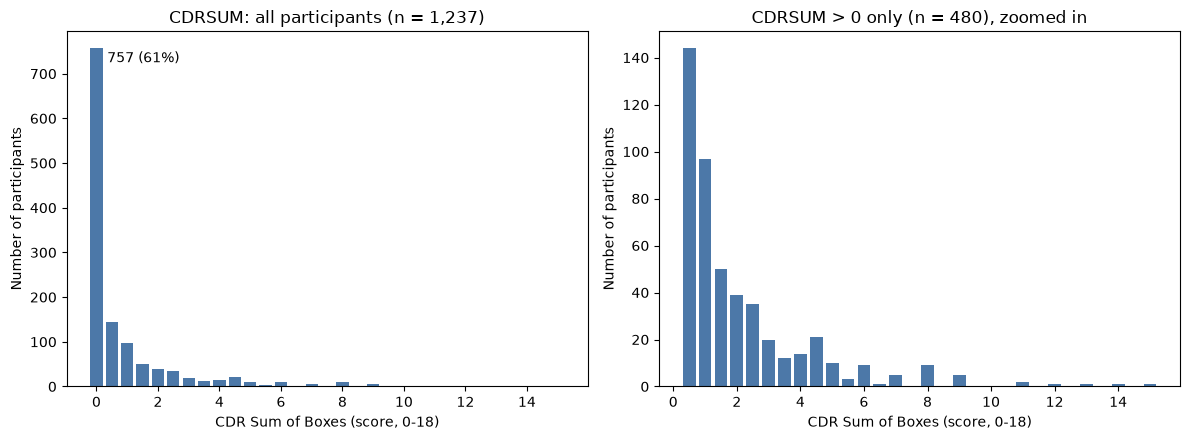

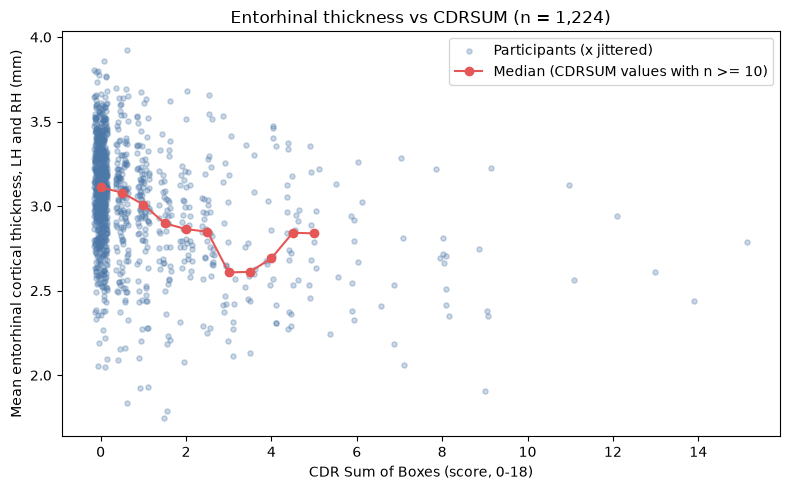

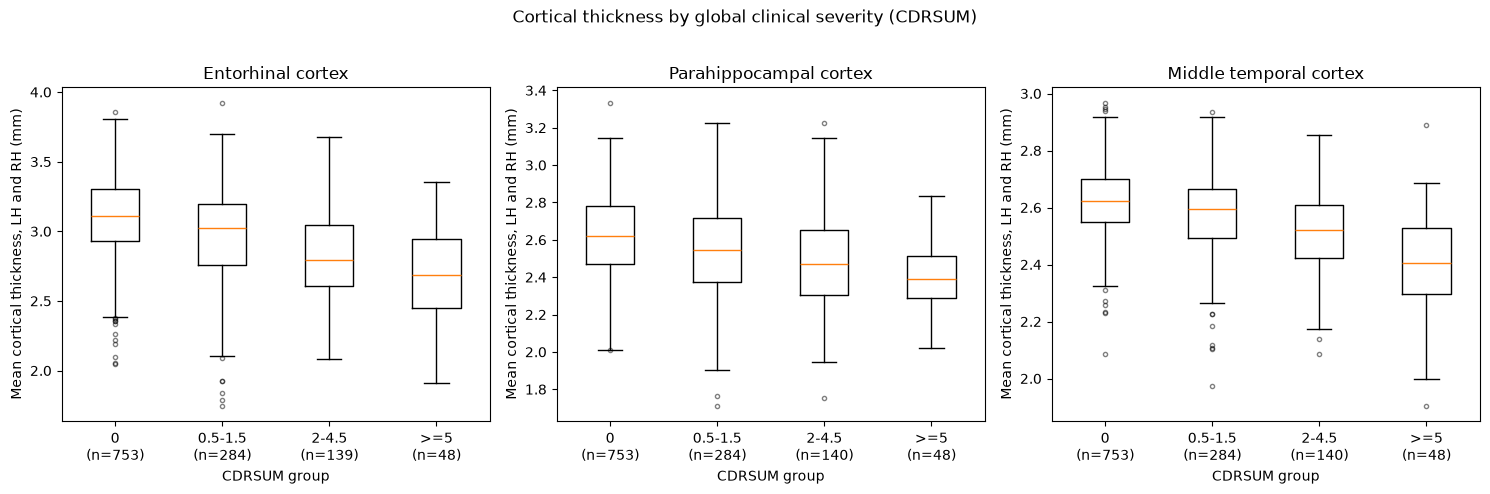

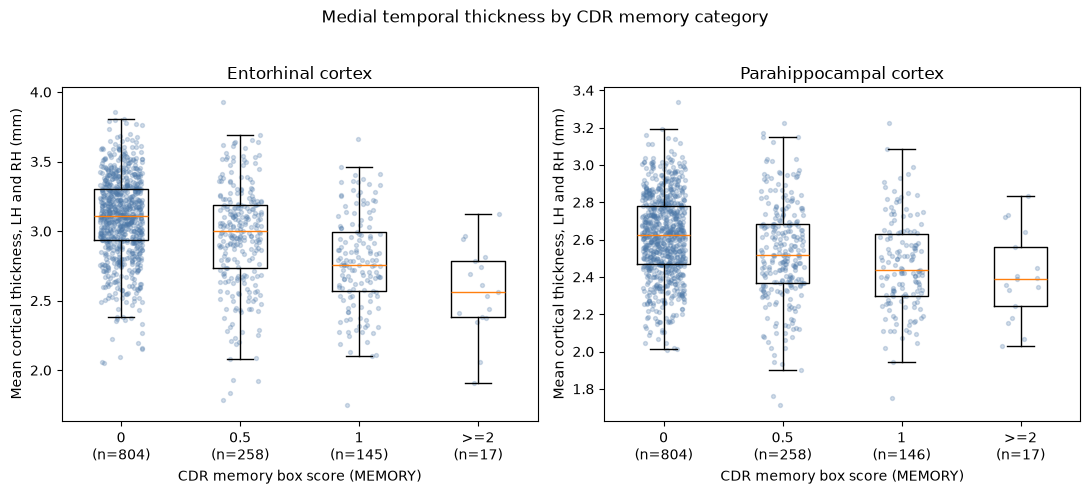

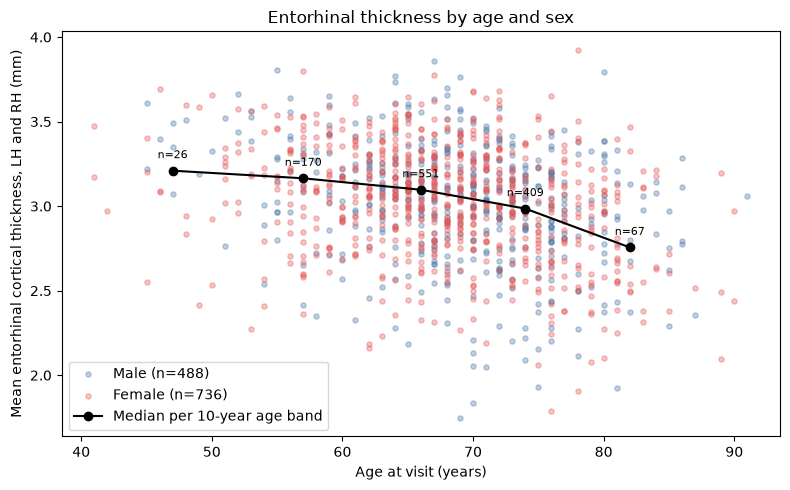

In [23]:
rng = np.random.default_rng(42)
BLUE, ORANGE = "#4C78A8", "#E45756"
regions = {"Entorhinal": "ENTORHINAL", "Parahippocampal": "PARAHIPPOCAMPAL", "Middle temporal": "MIDDLETEMPORAL"}

# ---- Figure 1: distribution of CDRSUM (discrete, zero-inflated) ----
vc = df["CDRSUM"].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(vc.index, vc.values, width=0.4, color=BLUE)
axes[0].text(0.35, vc.iloc[0] * 0.97, f"{vc.iloc[0]} ({vc.iloc[0] / vc.sum() * 100:.0f}%)", ha="left", va="center")
axes[0].set_title(f"CDRSUM: all participants (n = {vc.sum():,})")
pos = vc[vc.index > 0]
axes[1].bar(pos.index, pos.values, width=0.4, color=BLUE)
axes[1].set_title(f"CDRSUM > 0 only (n = {pos.sum()}), zoomed in")
for ax in axes:
    ax.set_xlabel("CDR Sum of Boxes (score, 0-18)")
    ax.set_ylabel("Number of participants")
plt.tight_layout(); plt.savefig(FIG / "fig1_cdrsum_distribution.png", dpi=200); plt.show()

# ---- Figure 2: CDRSUM vs entorhinal thickness (scatter + medians) ----
dd = df[["CDRSUM", "TH_ENTORHINAL"]].dropna()
x = dd["CDRSUM"] + rng.uniform(-0.15, 0.15, len(dd))          # jitter: scores are heavily tied
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, dd["TH_ENTORHINAL"], s=14, alpha=0.3, color=BLUE, label="Participants (x jittered)")
g = dd.groupby("CDRSUM")["TH_ENTORHINAL"].agg(["median", "size"])
g = g[g["size"] >= 10]
ax.plot(g.index, g["median"], "o-", color=ORANGE, label="Median (CDRSUM values with n >= 10)")
ax.set_xlabel("CDR Sum of Boxes (score, 0-18)")
ax.set_ylabel("Mean entorhinal cortical thickness, LH and RH (mm)")
ax.set_title(f"Entorhinal thickness vs CDRSUM (n = {len(dd):,})")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "fig2_entorhinal_vs_cdrsum.png", dpi=200); plt.show()

# ---- Figure 3: thickness of three regions by CDRSUM group (Q2) ----
cats = ["0", "0.5-1.5", "2-4.5", ">=5"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, (name, r) in zip(axes, regions.items()):
    data = [df.loc[df["CDR_group"] == c, f"TH_{r}"].dropna() for c in cats]
    ax.boxplot(data, flierprops=dict(markersize=3, alpha=0.5))
    ax.set_xticks(range(1, 5)); ax.set_xticklabels([f"{c}\n(n={len(v)})" for c, v in zip(cats, data)])
    ax.set_title(f"{name} cortex"); ax.set_xlabel("CDRSUM group")
    ax.set_ylabel("Mean cortical thickness, LH and RH (mm)")
fig.suptitle("Cortical thickness by global clinical severity (CDRSUM)", y=1.02)
plt.tight_layout(); plt.savefig(FIG / "fig3_thickness_by_cdrsum_group.png", dpi=200, bbox_inches="tight"); plt.show()

# ---- Figure 4: thickness by CDR memory score (Q3), with raw points ----
mcats = ["0", "0.5", "1", ">=2"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, (name, r) in zip(axes, [("Entorhinal", "ENTORHINAL"), ("Parahippocampal", "PARAHIPPOCAMPAL")]):
    data = [df.loc[df["MEM_group"] == c, f"TH_{r}"].dropna() for c in mcats]
    ax.boxplot(data, showfliers=False)
    for i, v in enumerate(data, start=1):
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(v)), v, s=8, alpha=0.25, color=BLUE)
    ax.set_xticks(range(1, 5)); ax.set_xticklabels([f"{c}\n(n={len(v)})" for c, v in zip(mcats, data)])
    ax.set_title(f"{name} cortex"); ax.set_xlabel("CDR memory box score (MEMORY)")
    ax.set_ylabel("Mean cortical thickness, LH and RH (mm)")
fig.suptitle("Medial temporal thickness by CDR memory category", y=1.02)
plt.tight_layout(); plt.savefig(FIG / "fig4_thickness_by_memory.png", dpi=200, bbox_inches="tight"); plt.show()

# ---- Figure 5: age vs entorhinal thickness (covariate) ----
da = df[["NACCAGE", "TH_ENTORHINAL", "SEX"]].dropna()
fig, ax = plt.subplots(figsize=(8, 5))
for code, label, col in [(1, "Male", BLUE), (2, "Female", ORANGE)]:
    s = da[da["SEX"] == code]
    ax.scatter(s["NACCAGE"], s["TH_ENTORHINAL"], s=14, alpha=0.35, color=col, label=f"{label} (n={len(s)})")
band = pd.cut(da["NACCAGE"], bins=range(40, 100, 10))
m = da.groupby(band, observed=True).agg(age=("NACCAGE", "median"), th=("TH_ENTORHINAL", "median"), n=("NACCAGE", "size"))
ax.plot(m["age"], m["th"], "k-o", label="Median per 10-year age band")
for _, row in m.iterrows():
    ax.annotate(f"n={int(row['n'])}", (row["age"], row["th"]), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8)
ax.set_xlabel("Age at visit (years)"); ax.set_ylabel("Mean entorhinal cortical thickness, LH and RH (mm)")
ax.set_title("Entorhinal thickness by age and sex"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "fig5_entorhinal_by_age_sex.png", dpi=200); plt.show()

## 6. Figures

| Figure | Variables | Plot type | Reason |
|---|---|---|---|
| 1 | `CDRSUM` | Bar chart (two panels) | Discrete, zero-inflated score; the second panel makes the tail visible |
| 2 | `CDRSUM` × entorhinal thickness | Scatter with jitter and medians | Two quantitative variables with many ties |
| 3 | Thickness (3 regions) × CDRSUM group | Boxplots | Quantitative outcome across ordered groups |
| 4 | Thickness × `MEMORY` | Boxplots with raw points | Ordinal exposure; the group `≥ 2` has only 17 participants |
| 5 | Age × entorhinal thickness, by sex | Scatter with medians | Shows the covariate (confounder) structure |

**Figure 1.** `CDRSUM` is discrete (steps of 0.5) and strongly zero-inflated: 757 participants (61%) score 0 and the right tail reaches 15.

**Figure 2.** Median entorhinal thickness decreases from about 3.1 mm (CDRSUM = 0) to about 2.6 mm (CDRSUM ≈ 4–5), but individual values at each level spread from about 2.0 to 3.5 mm: the relationship is a trend, not a separation.

**Figure 3.** Median thickness declines across CDRSUM groups in all three regions. The y-axis range differs between panels, so the visual size of the shifts is not comparable across regions. Some participants with CDRSUM = 0 have low entorhinal thickness (≈ 2.0–2.4 mm).

**Figure 4.** Entorhinal thickness declines stepwise with the memory score (median 3.11 → 3.00 → 2.76 → 2.56 mm); parahippocampal thickness declines more gently (2.62 → 2.39 mm).

**Figure 5.** Thickness declines with age (median ≈ 3.2 mm in the 40s to ≈ 2.8 mm in the 80s), more steeply after about 70 years, with no visible difference between men and women. Because older participants are also more impaired, this pattern mixes age and disease effects.

In [24]:
th_cols3 = ["TH_ENTORHINAL", "TH_PARAHIPPOCAMPAL", "TH_MIDDLETEMPORAL"]

for g in ["CDR_group", "MEM_group"]:
    grp = df.groupby(g, observed=True)
    t = grp[th_cols3 + ["NACCAGE", "EDUC"]].agg(med_iqr)
    t.insert(0, "n", grp.size())
    t["% female"] = grp["SEX"].apply(lambda s: round((s == 2).mean() * 100, 1))
    print(f"\n=== Median (Q1-Q3) by {g} ===\n{t.to_string()}")

grp = df.groupby("SEX")
t = grp[th_cols3 + ["CDRSUM", "NACCAGE"]].agg(med_iqr)
t.insert(0, "n", grp.size())
print(f"\n=== Median (Q1-Q3) by SEX (1 = male, 2 = female) ===\n{t.to_string()}")

# Spearman correlations (descriptive)
exposures = ["CDRSUM", "MEMORY", "CDR_nonmemory", "NACCAGE", "EDUC"]
print("\nSpearman rho: bilateral thickness (rows) vs clinical variables and age")
print(pd.DataFrame({r: {v: rho(df, f"TH_{r}", v) for v in exposures}
                    for r in ("ENTORHINAL", "PARAHIPPOCAMPAL", "MIDDLETEMPORAL")}).T.round(2))

z = df[df["CDRSUM"] == 0]
print(f"\nCDRSUM == 0 only (n = {len(z)}): Spearman, thickness vs age")
print(pd.Series({r: rho(z, f"TH_{r}", "NACCAGE") for r in ("ENTORHINAL", "PARAHIPPOCAMPAL", "MIDDLETEMPORAL")}).round(2))

print("\nSpearman LH vs RH:", {r: round(rho(df, f"LH_{r}_AVGTH", f"RH_{r}_AVGTH"), 2)
                              for r in ("ENTORHINAL", "PARAHIPPOCAMPAL", "MIDDLETEMPORAL")})
print("Spearman CDRSUM vs MEMORY:", round(rho(df, "CDRSUM", "MEMORY"), 2),
      "| MEMORY vs CDR_nonmemory:", round(rho(df, "MEMORY", "CDR_nonmemory"), 2))
print("\nCDR_nonmemory:", df["CDR_nonmemory"].describe().round(2).to_dict(), "| zeros:", int((df["CDR_nonmemory"] == 0).sum()))


=== Median (Q1-Q3) by CDR_group ===
             n     TH_ENTORHINAL TH_PARAHIPPOCAMPAL TH_MIDDLETEMPORAL              NACCAGE                 EDUC  % female
CDR_group                                                                                                                
0          757  3.11 (2.93-3.30)   2.62 (2.47-2.78)  2.62 (2.55-2.70)  67.00 (63.00-72.00)  16.00 (15.00-18.00)      63.7
0.5-1.5    291  3.02 (2.76-3.20)   2.54 (2.37-2.72)  2.59 (2.49-2.67)  71.00 (66.00-76.00)  16.00 (14.00-18.00)      54.0
2-4.5      141  2.79 (2.61-3.05)   2.47 (2.31-2.65)  2.52 (2.42-2.61)  71.00 (64.00-76.00)  16.00 (14.00-18.00)      48.9
>=5         48  2.69 (2.45-2.94)   2.39 (2.29-2.51)  2.40 (2.30-2.53)  70.50 (61.75-76.25)  16.00 (14.00-18.00)      66.7

=== Median (Q1-Q3) by MEM_group ===
             n     TH_ENTORHINAL TH_PARAHIPPOCAMPAL TH_MIDDLETEMPORAL              NACCAGE                 EDUC  % female
MEM_group                                                               

In [25]:

if df.columns.duplicated().any():

    df = df.loc[:, ~df.columns.duplicated()]


mem_value = df["MEMORY"].iloc[:, 0] if isinstance(df["MEMORY"], pd.DataFrame) else df["MEMORY"]
non_value = df["CDR_nonmemory"].iloc[:, 0] if isinstance(df["CDR_nonmemory"], pd.DataFrame) else df["CDR_nonmemory"]

valid = mem_value.notna() & non_value.notna()
mem = mem_value.gt(0)
non = non_value.gt(0)

order = ["None", "Memory only", "Non-memory only", "Both"]
conditions = [
    valid & ~mem & ~non,
    valid &  mem & ~non,
    valid & ~mem &  non,
    valid &  mem &  non,
]

df["Impairment_profile"] = np.select(conditions, order, default="Unknown")


profile_df = df.loc[df["Impairment_profile"].isin(order)].copy()

g = profile_df.groupby("Impairment_profile", observed=False)
t = g[["TH_ENTORHINAL", "TH_PARAHIPPOCAMPAL", "NACCAGE"]].agg(med_iqr).reindex(order)
t.insert(0, "n", g.size().reindex(order, fill_value=0))

print("Median (Q1-Q3) by CDR impairment profile:")
print(t.to_string())


Median (Q1-Q3) by CDR impairment profile:
                      n     TH_ENTORHINAL TH_PARAHIPPOCAMPAL              NACCAGE
Impairment_profile                                                               
None                757  3.11 (2.93-3.30)   2.62 (2.47-2.78)  67.00 (63.00-72.00)
Memory only         114  3.03 (2.78-3.19)   2.60 (2.41-2.73)  71.00 (66.00-76.00)
Non-memory only      51  3.13 (2.91-3.28)   2.62 (2.47-2.75)  70.00 (66.00-73.50)
Both                315  2.86 (2.62-3.12)   2.46 (2.32-2.64)  71.00 (64.00-76.00)


Median (Q1-Q3) by CDR impairment profile:
                      n     TH_ENTORHINAL TH_PARAHIPPOCAMPAL              NACCAGE
Impairment_profile                                                               
None                757  3.11 (2.93-3.30)   2.62 (2.47-2.78)  67.00 (63.00-72.00)
Memory only         114  3.03 (2.78-3.19)   2.60 (2.41-2.73)  71.00 (66.00-76.00)
Non-memory only      51  3.13 (2.91-3.28)   2.62 (2.47-2.75)  70.00 (66.00-73.50)
Both                315  2.86 (2.62-3.12)   2.46 (2.32-2.64)  71.00 (64.00-76.00)


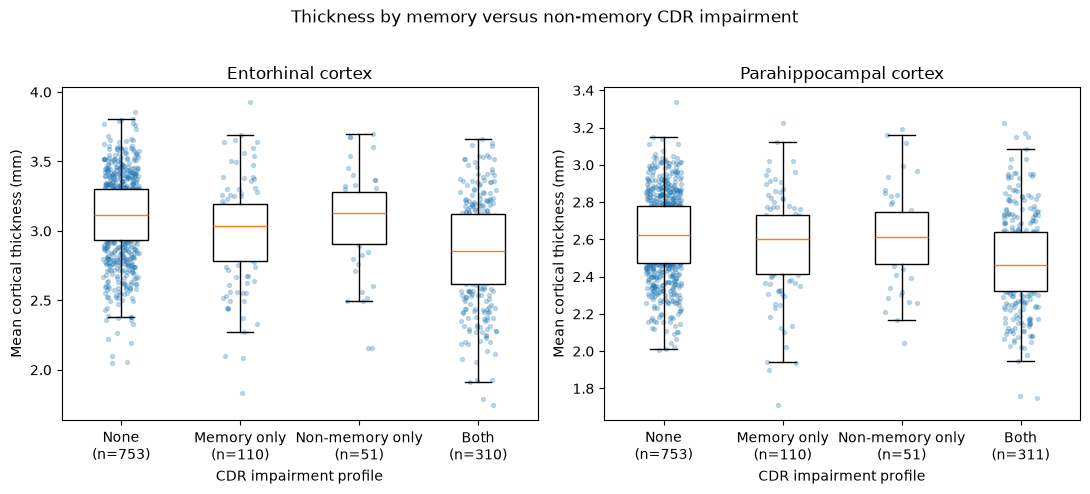

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path


FIG = Path("./figures")
FIG.mkdir(exist_ok=True)
BLUE = "#1f77b4" 
rng = np.random.default_rng(42) 


def med_iqr(x):
    q1, med, q3 = x.quantile([0.25, 0.5, 0.75])
    return f"{med:.2f} ({q1:.2f}-{q3:.2f})"
mem_value = df["MEMORY"]
non_value = df["CDR_nonmemory"]

valid = mem_value.notna() & non_value.notna()
mem = mem_value.gt(0)
non = non_value.gt(0)

order = ["None", "Memory only", "Non-memory only", "Both"]
conditions = [
    valid & ~mem & ~non,
    valid &  mem & ~non,
    valid & ~mem &  non,
    valid &  mem &  non,
]

df["Impairment_profile"] = np.select(
    conditions,
    order,
    default="Unknown"
)




g = df.groupby("Impairment_profile")
t = g[["TH_ENTORHINAL", "TH_PARAHIPPOCAMPAL", "NACCAGE"]].agg(med_iqr).reindex(order)
t.insert(0, "n", g.size().reindex(order))
print("Median (Q1-Q3) by CDR impairment profile:"); print(t.to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, (name, v) in zip(axes, [("Entorhinal", "TH_ENTORHINAL"), ("Parahippocampal", "TH_PARAHIPPOCAMPAL")]):
  
    data = [df.loc[df["Impairment_profile"] == p, v].dropna() for p in order]
 
    bp = ax.boxplot(data, showfliers=False, patch_artist=True)
  
    for patch in bp['boxes']: patch.set_facecolor('white')

    for i, s in enumerate(data, start=1):
        ax.scatter(i + rng.uniform(-0.15, 0.15, len(s)), s, s=8, alpha=0.25, color=BLUE)
        
    ax.set_xticks(range(1, 5)); ax.set_xticklabels([f"{p}\n(n={len(s)})" for p, s in zip(order, data)])
    ax.set_title(f"{name} cortex"); ax.set_xlabel("CDR impairment profile")
    ax.set_ylabel("Mean cortical thickness (mm)")

fig.suptitle("Thickness by memory versus non-memory CDR impairment", y=1.02)
plt.tight_layout(); plt.savefig(FIG / "fig7_thickness_by_impairment_profile.png", dpi=200, bbox_inches="tight"); plt.show()


In [27]:
key_uds = ["NACCAGE", "SEX", "EDUC", "NACCUDSD", "CDRSUM", "MEMORY", "MOCATOTS", "NACCGDS", "DEP2YRS", "IADL_prorated"]
key_mri = ["TH_ENTORHINAL", "TH_PARAHIPPOCAMPAL", "TH_MIDDLETEMPORAL",
           "LH_ENTORHINAL_AVGTH", "RH_ENTORHINAL_AVGTH", "LH_PARAHIPPOCAMPAL_AVGTH",
           "RH_PARAHIPPOCAMPAL_AVGTH", "LH_MIDDLETEMPORAL_AVGTH", "RH_MIDDLETEMPORAL_AVGTH"]
miss = pd.DataFrame({"Face": ["UDS"] * len(key_uds) + ["MRI"] * len(key_mri), "Variable": key_uds + key_mri})
miss["Missing n"] = miss["Variable"].map(df.isna().sum())
miss["Missing %"] = (miss["Missing n"] / len(df) * 100).round(1)
print(miss.to_string(index=False))

mri_all = [c for c in df.columns if c.startswith(("LH_", "RH_")) and c.endswith(("_AVGTH", "_GVOL"))]
assert len(mri_all) == 124

def compare(flag):
    rows = {}
    for lab, g in df.groupby(flag):
        rows[lab] = {"n": len(g), "Age": med_iqr(g["NACCAGE"]), "Education": med_iqr(g["EDUC"]),
                     "% female": round((g["SEX"] == 2).mean() * 100, 1),
                     "% normal": round((g["NACCUDSD"] == 1).mean() * 100, 1),
                     "% MCI": round((g["NACCUDSD"] == 3).mean() * 100, 1),
                     "% dementia": round((g["NACCUDSD"] == 4).mean() * 100, 1),
                     "CDRSUM": med_iqr(g["CDRSUM"])}
    return pd.DataFrame(rows).T

print("\nParticipants with vs without a MoCA score:")
print(compare(np.where(df["MOCATOTS"].notna(), "MoCA available", "MoCA missing")).to_string())
print("\nParticipants with vs without usable MRI (12 unreliable scans removed):")
print(compare(np.where(df[mri_all].isna().all(axis=1), "No usable MRI", "Usable MRI")).to_string())

Face                 Variable  Missing n  Missing %
 UDS                  NACCAGE          0        0.0
 UDS                      SEX          0        0.0
 UDS                     EDUC          2        0.2
 UDS                 NACCUDSD          0        0.0
 UDS                   CDRSUM          0        0.0
 UDS                   MEMORY          0        0.0
 UDS                 MOCATOTS        253       20.5
 UDS                  NACCGDS         14        1.1
 UDS                  DEP2YRS         16        1.3
 UDS            IADL_prorated         19        1.5
 MRI            TH_ENTORHINAL         13        1.1
 MRI       TH_PARAHIPPOCAMPAL         12        1.0
 MRI        TH_MIDDLETEMPORAL         12        1.0
 MRI      LH_ENTORHINAL_AVGTH         13        1.1
 MRI      RH_ENTORHINAL_AVGTH         13        1.1
 MRI LH_PARAHIPPOCAMPAL_AVGTH         12        1.0
 MRI RH_PARAHIPPOCAMPAL_AVGTH         12        1.0
 MRI  LH_MIDDLETEMPORAL_AVGTH         12        1.0
 MRI  RH_MID

**Missingness of key variables.**

| Variable | File | Missing n | Missing % |
|---|---|---|---|
| `NACCAGE`, `SEX`, `NACCUDSD`, `CDRSUM`, `MEMORY` | UDS | 0 | 0.0 |
| `EDUC` | UDS | 2 | 0.2 |
| `NACCGDS` | UDS | 14 | 1.1 |
| `DEP2YRS` | UDS | 16 | 1.3 |
| `IADL_prorated` | UDS | 19 | 1.5 |
| `MOCATOTS` | UDS | 253 | 20.5 |
| Entorhinal thickness (bilateral mean; LH and RH separately) | MRI | 13 | 1.1 |
| Parahippocampal and middle temporal thickness (bilateral mean; LH and RH) | MRI | 12 | 1.0 |

UDS variables are almost complete except `MOCATOTS`. MRI thickness variables are missing for about 1.0–1.1% of participants.

                         n    min  median     max    IQR  below fence  above fence
CDRSUM              1237.0  0.000   0.000  15.000  1.000          0.0        115.0
MOCATOTS             984.0  0.000  25.000  30.000  5.000         48.0          0.0
TH_ENTORHINAL       1224.0  1.747   3.060   3.925  0.444         15.0          1.0
TH_PARAHIPPOCAMPAL  1225.0  1.711   2.583   3.335  0.325          5.0          1.0
TH_MIDDLETEMPORAL   1225.0  1.904   2.598   2.968  0.164         32.0          5.0


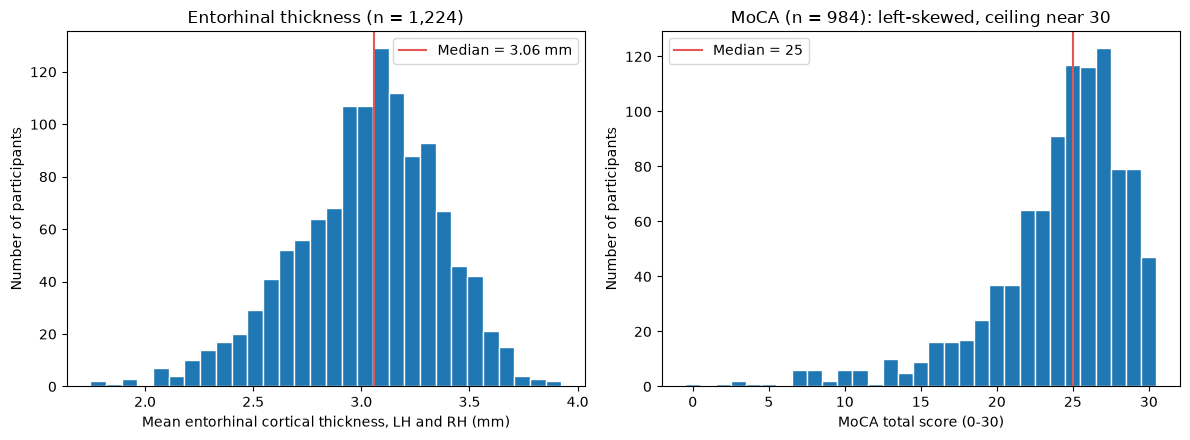

In [28]:
def tukey(s):
    s = s.dropna(); q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return {"n": len(s), "min": s.min(), "median": s.median(), "max": s.max(), "IQR": iqr,
            "below fence": int((s < lo).sum()), "above fence": int((s > hi).sum())}
print(pd.DataFrame({v: tukey(df[v]) for v in ["CDRSUM", "MOCATOTS", "TH_ENTORHINAL", "TH_PARAHIPPOCAMPAL", "TH_MIDDLETEMPORAL"]}).T.round(3).to_string())

# ---- Figure 6: distribution of one quantitative MRI variable and one cognitive score ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
s = df["TH_ENTORHINAL"].dropna()
axes[0].hist(s, bins=30, color=BLUE, edgecolor="white")
axes[0].axvline(s.median(), color=ORANGE, label=f"Median = {s.median():.2f} mm"); axes[0].legend()
axes[0].set_xlabel("Mean entorhinal cortical thickness, LH and RH (mm)"); axes[0].set_ylabel("Number of participants")
axes[0].set_title(f"Entorhinal thickness (n = {len(s):,})")
m = df["MOCATOTS"].dropna()
axes[1].hist(m, bins=np.arange(-0.5, 31.5, 1), color=BLUE, edgecolor="white")
axes[1].axvline(m.median(), color=ORANGE, label=f"Median = {m.median():.0f}"); axes[1].legend()
axes[1].set_xlabel("MoCA total score (0-30)"); axes[1].set_ylabel("Number of participants")
axes[1].set_title(f"MoCA (n = {len(m):,}): left-skewed, ceiling near 30")
plt.tight_layout(); plt.savefig(FIG / "fig6_distributions_entorhinal_moca.png", dpi=200); plt.show()

## 6b. Shared cognitive and imaging summary (J5)

One clinical score (`CDRSUM`), one cognitive score (`MOCATOTS`) and the cortical thickness of three regions are described with tables (Sections 3, 5), Figures 1, 3 and 6 and the table of unusual points below.

- **Range, centre, spread.** `CDRSUM`: 0–15, median 0, IQR 0–1 (61.2% zeros). `MOCATOTS`: 0–30, median 25 (22–27), left-skewed with a ceiling effect. Entorhinal thickness (mean of both hemispheres): median ≈ 3.1 mm with approximately symmetric spread and a left tail (atrophy).
- **Unusual points.** - **Unusual points.** Points beyond the 1.5 × IQR fences (below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR):

| Variable | n | Below fence | Above fence |
|---|---|---|---|
| `CDRSUM` | 1,237 | 0 | 115 |
| `MOCATOTS` | 984 | 48 | 0 |
| Entorhinal thickness | 1,224 | 15 | 1 |
| Parahippocampal thickness | 1,225 | 5 | 1 |
| Middle temporal thickness | 1,225 | 32 | 5 |

For `CDRSUM` the fences are not informative: Q1 = 0 and Q3 = 1, so every score above 2.5 is flagged, although these are the participants with more severe impairment, not errors. For `MOCATOTS`, the 48 low scores (below 14.5) are the impaired participants. For the brain measures, the low values are the more atrophic participants and are plausible; they were not removed.

In [29]:
raw_uds = pd.read_csv(RAW / "udslong_imputed.csv", dtype={"NACCID": "string"}, low_memory=False)
raw_mri = pd.read_csv(RAW / "mriscanclean.csv", dtype={"NACCID": "string"}, low_memory=False)
for name, d in [("UDS (raw)", raw_uds), ("MRI (raw)", raw_mri)]:
    print(f"{name}: {len(d):,} rows | {d['NACCID'].nunique():,} unique participants | duplicated IDs: {int(d['NACCID'].duplicated().sum())}")

visit_cols = [c for c in ["NACCVNUM", "NACCAVST", "VISITYR", "VISITMO", "VISITDAY", "NACCFDYS", "NACCDAYS"] if c in raw_uds.columns]
print("\nVisit-related columns in the UDS file:", visit_cols or "none found")
if "NACCVNUM" in raw_uds.columns:
    print("\nVisit number of the row kept (NACCVNUM):"); print(raw_uds["NACCVNUM"].value_counts().sort_index())
if "NACCAVST" in raw_uds.columns:
    print("\nTotal UDS visits per participant (NACCAVST):")
    one = raw_uds.drop_duplicates("NACCID")["NACCAVST"]
    print(one.describe().round(2)); print(one.value_counts().sort_index())
if "VISITYR" in raw_uds.columns:
    print("\nVisit year range:", int(raw_uds["VISITYR"].min()), "-", int(raw_uds["VISITYR"].max()))

UDS (raw): 1,237 rows | 1,237 unique participants | duplicated IDs: 0
MRI (raw): 1,237 rows | 1,237 unique participants | duplicated IDs: 0

Visit-related columns in the UDS file: none found


## 7. Preliminary descriptive comparison (no inference)

Median (Q1–Q3) of bilateral cortical thickness (mm) by CDRSUM group:

| CDRSUM group | n | Entorhinal | Parahippocampal | Middle temporal | Age (median) | % female |
|---|---|---|---|---|---|---|
| 0 | 757 | 3.11 (2.93–3.30) | 2.62 (2.47–2.78) | 2.62 (2.55–2.70) | 67 | 63.7 |
| 0.5–1.5 | 291 | 3.02 (2.76–3.20) | 2.54 (2.37–2.72) | 2.59 (2.49–2.67) | 71 | 54.0 |
| 2–4.5 | 141 | 2.79 (2.61–3.05) | 2.47 (2.31–2.65) | 2.52 (2.42–2.61) | 71 | 48.9 |
| ≥ 5 | 48 | 2.69 (2.45–2.94) | 2.39 (2.29–2.51) | 2.40 (2.30–2.53) | 70.5 | 66.7 |

By CDR memory score:

| MEMORY | n | Entorhinal | Parahippocampal | Age (median) | % female |
|---|---|---|---|---|---|
| 0 | 808 | 3.11 (2.93–3.30) | 2.62 (2.47–2.78) | 67 | 64.2 |
| 0.5 | 264 | 3.00 (2.74–3.19) | 2.52 (2.37–2.69) | 71 | 49.2 |
| 1 | 148 | 2.76 (2.57–3.00) | 2.44 (2.30–2.63) | 70.5 | 51.4 |
| ≥ 2 | 17 | 2.56 (2.38–2.79) | 2.39 (2.25–2.56) | 71 | 88.2 |

**Rank correlations (Spearman ρ, bilateral mean thickness).**

| Region | CDRSUM | MEMORY | CDR non-memory | Age | Education |
|---|---|---|---|---|---|
| Entorhinal | −0.31 | −0.32 | −0.28 | −0.28 | 0.04 |
| Parahippocampal | −0.25 | −0.24 | −0.24 | −0.20 | 0.03 |
| Middle temporal | −0.31 | −0.31 | −0.29 | −0.24 | 0.07 |

Among participants with CDRSUM = 0 (n = 757), thickness still correlates with age (ρ = −0.28, −0.21, −0.28), so age has an effect comparable to that of clinical severity. Left and right thickness correlate moderately (ρ = 0.65–0.71), so the bilateral mean is a reasonable summary but hemispheres are not redundant. `CDRSUM` and `MEMORY` are almost the same variable (ρ = 0.94), and `MEMORY` and `CDR_nonmemory` correlate at ρ = 0.76; 871 participants (70.4%) have `CDR_nonmemory = 0`.

**Observations (descriptive only).**
- Median thickness decreases monotonically in all three regions with higher CDRSUM and with a higher memory score (differences between the lowest and highest CDRSUM groups: about 0.42 mm entorhinal, 0.23 mm parahippocampal, 0.22 mm middle temporal; in SD units the middle temporal shift, ≈ 1.5 SD, is the largest).
- The entorhinal cortex differs earlier (already at CDRSUM 2–4.5), the middle temporal cortex mainly in the ≥ 5 group. Interquartile ranges of adjacent groups overlap considerably: the pattern is a trend, not a separation.
- More impaired participants are about 4 years older, and thickness declines with age; age must be controlled. Median thickness differs very little between men and women.
- Thickness correlates with non-memory severity (ρ ≈ −0.28) almost as strongly as with memory severity (ρ ≈ −0.32), so these data give no clear descriptive evidence that memory impairment is *specifically* related to medial temporal thinning (see Figure 7).
- The group `MEMORY ≥ 2` has only 17 participants (88.2% women); its values must be interpreted with caution.

## 8. Final statistical question

Among the 1,237 participants in the NACC UDS–MRI subset, is a higher CDR Sum of Boxes (`CDRSUM`) associated with a thinner entorhinal cortex (mean of left and right), after taking age, sex and years of education into account?

**What is what**

| Part | Variable | Type |
|---|---|---|
| What we compare (clinical score) | `CDRSUM` (0 = no problems, higher = more impairment) | number, many zeros |
| What we measure in the brain | Entorhinal cortical thickness in mm (average of left and right) | continuous number |
| What we take into account | `NACCAGE`, `SEX`, `EDUC` | number, group, number |

**Also looked at (extra).** The same comparison for the parahippocampal and middle temporal cortex.

**Sample.** 1,222 of 1,237 participants have all needed values (98.8%).

### Why this question fits our data
- Almost no data are missing (98.8% complete).
- Participants range from healthy to dementia, so both CDRSUM and thickness vary.
- In the tables, median thickness falls as CDRSUM rises (3.11 mm for CDRSUM = 0 vs 2.69 mm for CDRSUM ≥ 5), so the question is not empty.
- Thickness does not depend much on head size, which matters because head size is not in our data.

### Limits to keep in mind
- The data are a single snapshot, so we can see that things go together but not what causes what.
- The participants come from research clinics, not from the general population.
- About 61% of participants have CDRSUM = 0, and only 48 have CDRSUM ≥ 5.
- Older people have lower scores and thinner cortex, so age has to be taken into account.
- The CDR memory score is almost the same variable as CDRSUM (ρ = 0.94), so it is not studied as a separate question.
- Some cleaning choices were judgement calls (12 scans removed, outlier limits); Section 2c shows the results change very little with other choices.

**Selected question: Q2.** It has the most complete data (98.8%). Q3 was merged into it because the CDR memory score is almost the same variable as CDRSUM (ρ = 0.94).